# Paper 3 figures

Run the setup cell, then the figure cells in this order.

1. Setup
2. Figure 1 study design
3. Figure 2 analysis flow
4. Figure 3 exposures
5. Figure 4 H1 and H3
6. Figure 5 H2
7. Figure 6 H4 and combined exposure
8. Figure 7 sound composition (merged epochs, not a hypothesis export)
9. Figures S1-S4 coverage, outcomes, traces, H5
10. Figure S5 H6 composites
11. Figure S6 screening diagnostics

Statistical tables are read only from `output/statistical_analysis/results`. Paths under `archive` are refused.


## Setup: imports, paths, study constants, shared helpers, phase colours

In [1]:
# Compact public exports; restore model context for existing figure code only.
def _read_result_csv(path, *args, **kwargs):
    result_table = pd.read_csv(path, *args, **kwargs)
    if "q_value" not in result_table.columns:
        return result_table
    from pathlib import Path
    aliases = {"q_value": "p_value_adjusted", "FDR_significant": "significant_adjusted",
               "predictor": "term", "comparison": "contrast", "grid_id": "hotspot_id",
               "n_grids": "n_hotspots", "test_statistic": "statistic"}
    result_table = result_table.rename(columns={key:current_values for key,current_values in aliases.items() if key in result_table.columns})
    source_path = Path(path)
    info = source_path.parent / (source_path.parent.name + "_run_info.csv")
    if info.exists():
        meta = pd.read_csv(info, dtype=str, keep_default_na=False)
        if set(["section", "item", "field", "value"]).issubset(meta.columns):
            prefix = source_path.name + "::"
            rows = meta[(meta.section == "result_context") & meta.item.str.startswith(prefix)]
            reference_fields = ["estimate", "std_error", "ci_lower", "ci_upper", "df", "statistic",
                                "p_value", "p_value_adjusted", "significant_adjusted", "n_observations", "n_participants"]
            promoted60 = source_path.name.endswith("Sensitivity_60s.csv") and rows.field.str.startswith("reference10s__").any()
            live60 = set()
            if promoted60:
                for field in reference_fields:
                    live60.add(field + "_60s")
                    result_table[field + "_60s"] = result_table[field] if field in result_table.columns else None
                    if field in result_table.columns:
                        result_table = result_table.drop(columns=[field])
            for field, group in rows.groupby("field", sort=False):
                if field in live60:
                    continue
                if field not in result_table.columns:
                    result_table[field] = None
                for item, value in zip(group.item, group.value):
                    index = int(item.rsplit("::", 1)[1]) - 1
                    if 0 <= index < len(result_table):
                        result_table.at[index, field] = value
            if promoted60:
                for field in reference_fields:
                    reference = "reference10s__" + field
                    result_table[field] = result_table[reference] if reference in result_table.columns else None
                    if reference in result_table.columns:
                        result_table = result_table.drop(columns=[reference])
    # Match pandas' original inference of numeric and Boolean fields.
    return pd.read_csv(io.StringIO(result_table.to_csv(index=False)), *args, **kwargs)

import io
import sys, os, re, hashlib, subprocess, textwrap
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyBboxPatch, Patch, Rectangle
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

from pathlib import Path

# ---- paths ----
# ROOT = project folder "Pranav Paper3_Final". The notebook lives in ROOT\scripts, so ROOT is the parent of the
# notebook's folder; the absolute PC path is the fallback.
_FALLBACK_ROOT = Path(r"C:\Users\sanga\Desktop\Pranav Paper3_Final")
_MERGED_REL = Path("output") / "merged_all_11participants_8min.csv"
ROOT = next((candidate_root for candidate_root in (Path.cwd().parent, Path.cwd(), _FALLBACK_ROOT) if (candidate_root / _MERGED_REL).exists()), _FALLBACK_ROOT)
OUT = ROOT / "Figures"
os.makedirs(OUT, exist_ok=True)
print("ROOT =", ROOT)
print("OUT  =", OUT)

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 7.5, "axes.titlesize": 8, "axes.labelsize": 7.5,
    "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "axes.linewidth": 0.6,
    "xtick.major.width": 0.5, "ytick.major.width": 0.5, "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "savefig.dpi": 300})

# ---- study constants (Paper3_common.R) ----
PARTICIPANTS = ["P4", "P8", "P9", "P10", "P11", "P12", "P13", "P14", "P15", "P16", "P17"]
PHASES = ["BikeU", "WalkU", "BikeG", "WalkG"]
PHASE_COL = {"BikeU": "#a50f15", "WalkU": "#f08a5d", "BikeG": "#006d2c", "WalkG": "#74c476"}
PHASE_LAB = {"BikeU": "Bike-Urban", "WalkU": "Walk-Urban", "BikeG": "Bike-Green", "WalkG": "Walk-Green"}
OUTCOMES = ["empatica_heart_rate", "empatica_eda_tonic", "empatica_eda_phasic", "empatica_skin_temperature",
    "empatica_hrv_td_sdnn", "empatica_hrv_td_rmssd", "empatica_hrv_fd_lf", "empatica_hrv_fd_hf",
    "empatica_hrv_fd_lf_hf_ratio", "empatica_hrv_fd_lfnu", "empatica_hrv_fd_hfnu", "empatica_hrv_fd_vlf",
    "empatica_hrv_fd_total_power",
    "eyetracker_pupil_diameter_avg", "eyetracker_pupil_change_rate", "eyetracker_blink_duration_s",
    "eyetracker_fixation_duration_s", "eyetracker_fixation_rate", "eyetracker_saccade_duration_s",
    "eyetracker_saccade_amplitude", "eyetracker_saccade_peak_velocity", "eyetracker_gaze_velocity",
    "eyetracker_gaze_dispersion", "eyetracker_distance_from_center", "eyetracker_gaze_centrality",
    "eyetracker_eyelid_aperture_avg"]
HRV_FD = OUTCOMES[6:13]
# clean_labels (H1_H3_core.R) without device prefix
LAB = {"empatica_heart_rate": "Heart rate (bpm)", "empatica_eda_tonic": "EDA tonic (SCL)", "empatica_eda_phasic": "EDA phasic (SCR)",
    "empatica_skin_temperature": "Skin temperature (°C)", "empatica_hrv_td_sdnn": "HRV SDNN (ms)", "empatica_hrv_td_rmssd": "HRV RMSSD (ms)",
    "empatica_hrv_fd_lf": "HRV LF power (ms²)", "empatica_hrv_fd_hf": "HRV HF power (ms²)", "empatica_hrv_fd_lf_hf_ratio": "HRV LF/HF ratio",
    "empatica_hrv_fd_lfnu": "HRV LF (nu)", "empatica_hrv_fd_hfnu": "HRV HF (nu)", "empatica_hrv_fd_vlf": "HRV VLF power (ms²)",
    "empatica_hrv_fd_total_power": "HRV total power (ms²)", "eyetracker_pupil_diameter_avg": "Pupil diameter (mm)",
    "eyetracker_pupil_change_rate": "Pupil change rate", "eyetracker_blink_duration_s": "Blink duration (s)",
    "eyetracker_fixation_duration_s": "Fixation duration (s)", "eyetracker_fixation_rate": "Fixation rate (/s)",
    "eyetracker_saccade_duration_s": "Saccade duration (s)", "eyetracker_saccade_amplitude": "Saccade amplitude (°)",
    "eyetracker_saccade_peak_velocity": "Saccade peak velocity (°/s)", "eyetracker_gaze_velocity": "Gaze velocity (°/s)",
    "eyetracker_gaze_dispersion": "Gaze dispersion", "eyetracker_distance_from_center": "Gaze distance from centre (px)",
    "eyetracker_gaze_centrality": "Gaze centrality", "eyetracker_eyelid_aperture_avg": "Eyelid aperture (mm)"}
SURVEYS = ["questionnaire_current_comfort_1_7", "questionnaire_pleasantness_1_5", "questionnaire_stai6_mean_1_5", "questionnaire_prs11_total_mean_1_5"]
SURVEY_LAB = {"questionnaire_current_comfort_1_7": "General comfort (1–7)", "questionnaire_pleasantness_1_5": "Pleasantness (1–5)",
    "questionnaire_stai6_mean_1_5": "State anxiety STAI-6 (1–5)", "questionnaire_prs11_total_mean_1_5": "Restorativeness PRS-11 (1–5)"}

USED = set()   # input files read, for provenance printout

RESULTS = ROOT / "output" / "statistical_analysis" / "results"

def src(rel, pc_rel):
    """pc_rel is relative to ROOT. Statistical tables must sit in the current results folder, never under archive."""
    candidate_path = ROOT.joinpath(*pc_rel.split("\\"))
    if not candidate_path.exists():
        raise FileNotFoundError(candidate_path)
    resolved = candidate_path.resolve()
    if "results" in [part.lower() for part in resolved.parts]:
        if "archive" in [part.lower() for part in resolved.parts]:
            raise RuntimeError("archived result refused: " + str(resolved))
        try:
            resolved.relative_to(RESULTS.resolve())
        except ValueError:
            raise RuntimeError("result is outside the current results folder: " + str(resolved))
    USED.add(str(resolved))
    return str(resolved)

# H1_H3_phaseavg combined outputs (output reduction 1 Nov 2026): return the rows of the former H1_Contrasts.csv /
# H3_Contrasts.csv / H2_Physio_Psycho_Concordance.csv, with the shared column names of Paper3_output_names.R.
def _reparse(t):   # filter on text, then parse like the former single-table CSV (same dtypes)
    import io
    return _read_result_csv(io.StringIO(t.to_csv(index=False)))

def h1h3_contrasts(hyp):
    results_table = _read_result_csv(src("res/H1_H3_Contrasts.csv", r"output\statistical_analysis\results\H1_H3_phaseavg\H1_H3_Contrasts.csv"), dtype=str, keep_default_na=False)
    results_table = results_table[(results_table.hypothesis == hyp) & (results_table.outcome_type == "Physiological")]
    return _reparse(results_table.drop(columns=["outcome_type", "outcome_family"]))

def h2_concordance():
    results_table = _read_result_csv(src("res/H2_Concordance.csv", r"output\statistical_analysis\results\H1_H3_phaseavg\H2_Concordance.csv"), dtype=str, keep_default_na=False)
    results_table = results_table[results_table.test == "H2_rmcorr_physio_psycho"]
    return _reparse(results_table.drop(columns=["test", "mode"]))

def md5(file_path):
    digest = hashlib.md5()
    with open(file_path, "rb") as input_stream:
        for b in iter(lambda: input_stream.read(1 << 20), b""): digest.update(b)
    return digest.hexdigest()

# ---------------- data ----------------
_cache = {}
def merged():
    if "m" in _cache: return _cache["m"]
    input_path = src("merged_all_11participants_8min.csv", r"output\merged_all_11participants_8min.csv")
    assert md5(input_path).startswith("d1566f"), "merged CSV is not the current d1566f file"
    epochs = _read_result_csv(input_path, low_memory=False)
    epochs = epochs[epochs.ParticipantID.isin(PARTICIPANTS) & epochs.PhaseID.isin(PHASES)].copy()
    epochs["Datetime"] = pd.to_datetime(epochs["Datetime"])        # clock time as stored in the CSV (time zone not documented in the scripts)
    epochs = epochs.sort_values(["ParticipantID", "PhaseID", "Datetime"])
    epochs["t_sec"] = epochs.groupby(["ParticipantID", "PhaseID"]).Datetime.transform(lambda x: (x - x.min()).dt.total_seconds())
    # bilateral / two-sensor averages exactly as Analysis_combined_core.R average_sources (rowMeans, na.rm=TRUE)
    avg = {"atmo_pm2.5_avg": ["atmo_lys_atmotube_left__atmotube_pm2.5", "atmo_lys_atmotube_right__atmotube_pm2.5"],
           "atmo_pm1_avg": ["atmo_lys_atmotube_left__atmotube_pm1", "atmo_lys_atmotube_right__atmotube_pm1"],
           "atmo_pm10_avg": ["atmo_lys_atmotube_left__atmotube_pm10", "atmo_lys_atmotube_right__atmotube_pm10"],
           "lys_lux_avg": ["atmo_lys_LYS1__lys_lux", "atmo_lys_LYS2__lys_lux"],
           "lys_kelvin_avg": ["atmo_lys_LYS1__lys_kelvin", "atmo_lys_LYS2__lys_kelvin"]}
    for key, current_values in avg.items(): epochs[key] = epochs[current_values].mean(axis=1, skipna=True)
    assert len(epochs) == 2112 and (epochs.groupby(["ParticipantID", "PhaseID"]).size() == 48).all()
    _cache["m"] = epochs; return epochs

def ln_outcomes():
    normalization_path = src("res/Normalization_H1toH4_all_parameters.csv",
            r"output\statistical_analysis\Normalization & Parameter Screening\Normalization\Normalization_H1toH4_all_parameters.csv")
    normalization_table = _read_result_csv(normalization_path).set_index("column_name")
    tr = normalization_table.loc[OUTCOMES, "transformation_in_models"]
    assert set(tr) <= {"Natural log", "No transformation"}
    return [outcome for outcome in OUTCOMES if tr[outcome] == "Natural log"]

def analysis_units(epochs):
    """Row-level ln(x) (x<=0 -> NA) for 'Natural log' outcomes (paper3_outcome_natural_log), others native."""
    analysis_epochs = epochs.copy()
    for outcome in ln_outcomes():
        x = analysis_epochs[outcome].astype(float); analysis_epochs[outcome] = np.where(np.isfinite(x) & (x > 0), np.log(x.where(x > 0)), np.nan)
    return analysis_epochs

def phase_means(epochs, cols):
    return epochs.groupby(["ParticipantID", "PhaseID"], as_index=False)[cols].mean()

def ulab(outcome):
    return ("ln " + LAB[outcome]) if outcome in ln_outcomes() else LAB[outcome]

# ---------------- helpers ----------------
def panel_label(ax, s, dx=-0.02, dy=0.01, fig=None, size=10):
    fig = fig or ax.figure
    bb = ax.get_position()
    fig.text(bb.x0 + dx, bb.y1 + dy, s, fontsize=size, fontweight="bold", ha="right", va="bottom")

def img_axes(ax, path, title=None):
    im = Image.open(path)
    im.draft("RGB", (1100, 1100))
    im = im.convert("RGB")
    im.thumbnail((1100, 1100))
    ax.imshow(np.asarray(im)); ax.set_axis_off()
    if title: ax.set_title(title, loc="left", fontsize=8)
    return im.size

def save(fig, name):
    png = OUT / (name + ".png"); pdf = OUT / (name + ".pdf")
    fig.savefig(png, dpi=300, facecolor="white"); fig.savefig(pdf, facecolor="white")
    plt.close(fig); print("saved", png, "and", pdf)
    try:   # show the saved PNG inline when run in Jupyter
        from IPython.display import display, Image as _IPImage
        display(_IPImage(filename=str(png), width=850))
    except Exception:
        pass

def bh(p):
    p = np.asarray(p, float); out = np.full(p.shape, np.nan); ok = np.isfinite(p); pp = p[ok]; n = len(pp)
    if n == 0: return out
    outcome = np.argsort(pp); q = pp[outcome] * n / np.arange(1, n + 1); q = np.minimum.accumulate(q[::-1])[::-1]
    r = np.empty(n); r[outcome] = np.minimum(q, 1); out[ok] = r; return out

def phase_legend(ax, loc="best", ncol=1, **kw):
    legend_handles = [Line2D([], [], marker="o", ls="", color=PHASE_COL[phase], label=PHASE_LAB[phase] + f" ({phase})", markersize=4.5) for phase in PHASES]
    return ax.legend(handles=legend_handles, loc=loc, ncol=ncol, frameon=False, **kw)

def strip_box(ax, data_by_phase, pos=None, width=0.6, log=False):
    pos = pos or list(range(len(PHASES)))
    vals = [np.asarray(current_values, float)[np.isfinite(np.asarray(current_values, float))] for current_values in data_by_phase]
    bp = ax.boxplot(vals, positions=pos, widths=width, patch_artist=True, showfliers=False, whis=(5, 95),
                    medianprops=dict(color="black", lw=0.8), boxprops=dict(lw=0.5), whiskerprops=dict(lw=0.5), capprops=dict(lw=0.5))
    for b, local_phase in zip(bp["boxes"], PHASES): b.set_facecolor(PHASE_COL[local_phase]); b.set_alpha(0.45)
    return bp


ROOT = c:\Users\sanga\Desktop\Pranav Paper3_Final
OUT  = c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures


## Figure 1 — Study design (route map, session timeline, sensor setup)

Inputs (relative to `ROOT`):
* `Figures\route_maps\Route Plan for Experiment_standard_09Jun2026.jpg`
* `Figures\manuscript_figures\Experiment timeline.png`
* `Figures\sensor_setup\Experiment Sensor Setup.jpg`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure1_study_design.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure1_study_design.pdf


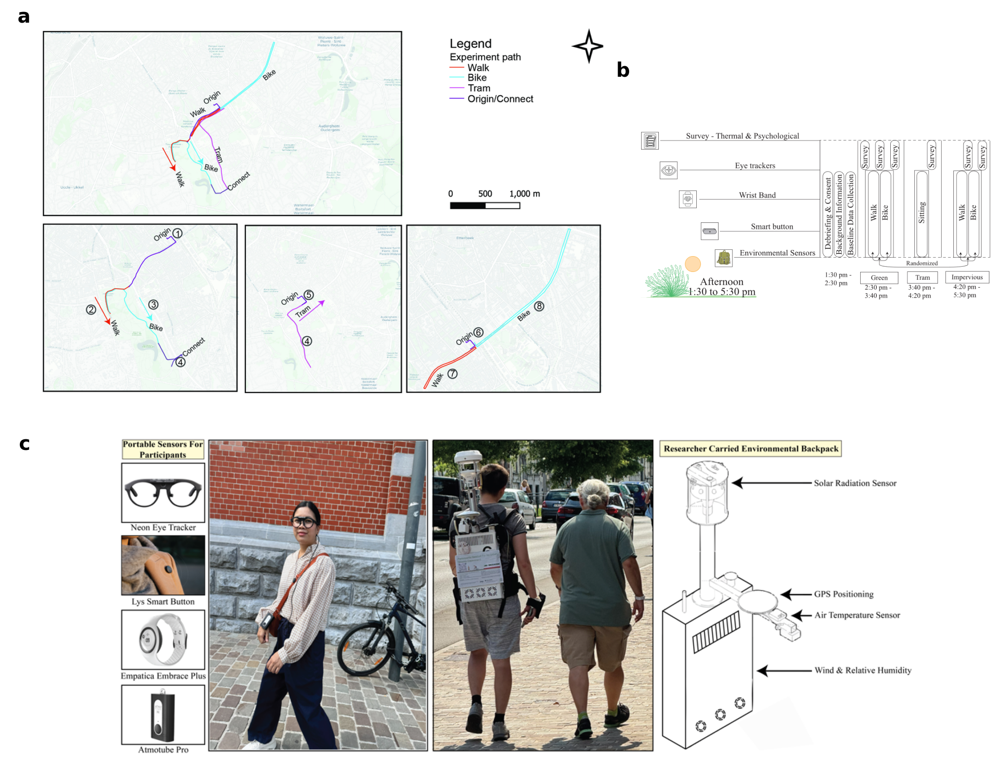

In [2]:
# Figure 1 — study design (existing artwork)
def fig1():
    route = src("art/route_map.jpg", r"Figures\route_maps\Route Plan for Experiment_standard_09Jun2026.jpg")
    tl = src("art/Experiment timeline.png", r"Figures\manuscript_figures\Experiment timeline.png")
    sens = src("art/Experiment Sensor Setup.jpg", r"Figures\sensor_setup\Experiment Sensor Setup.jpg")
    fig = plt.figure(figsize=(7.2, 5.5))
    ax_a = fig.add_axes([0.035, 0.455, 0.575, 0.535]); img_axes(ax_a, route)
    ax_b = fig.add_axes([0.635, 0.52, 0.36, 0.40]); img_axes(ax_b, tl)
    ax_c = fig.add_axes([0.035, 0.01, 0.96, 0.42]); img_axes(ax_c, sens)
    for ax, s_ in [(ax_a, "a"), (ax_b, "b"), (ax_c, "c")]:
        bb = ax.get_window_extent().transformed(fig.transFigure.inverted())
        fig.text(bb.x0 - 0.005, bb.y1, s_, fontsize=10, fontweight="bold", ha="right", va="top")
    save(fig, "Figure1_study_design")

try:
    fig1()
except MemoryError:
    print('Figure 1 artwork skipped: image too large for this session')


## Figure 2 — Analysis flow

Counts come from the current results folder.


saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure2_analysis_flow.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure2_analysis_flow.pdf


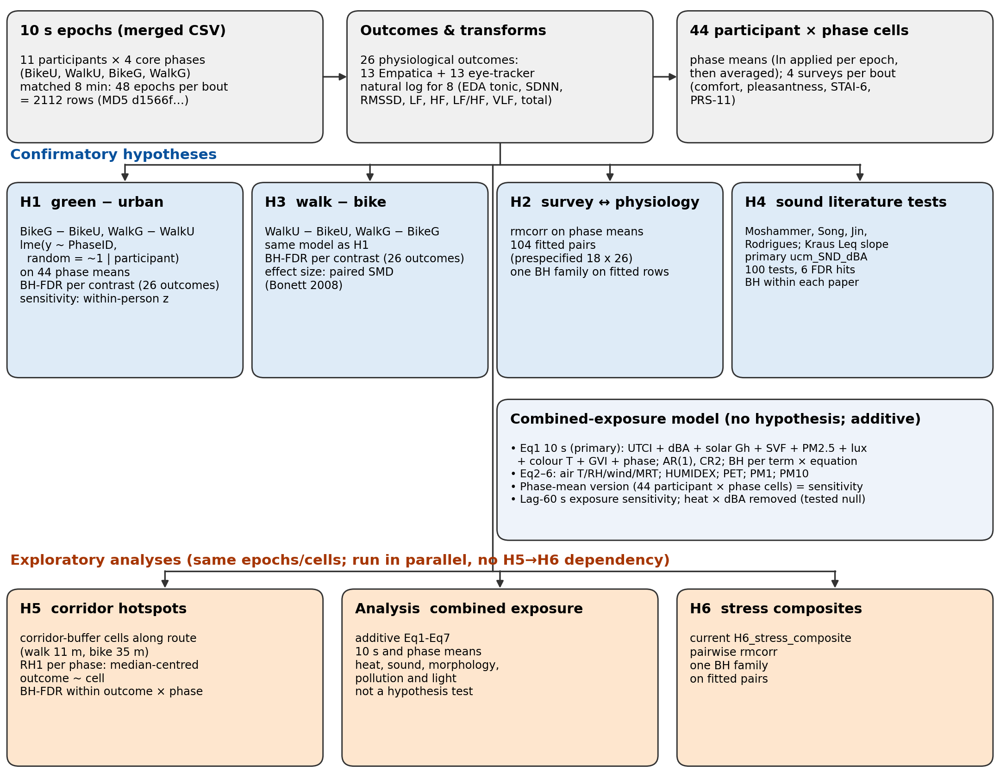

In [3]:
# Figure 2 — analysis flow (schematic; every number checked against data/outputs)
def fig2():
    plot_data = merged()
    n_rows = len(plot_data); n_cells = plot_data.groupby(["ParticipantID", "PhaseID"]).ngroups
    lnout = ln_outcomes()
    h1 = h1h3_contrasts("H1")
    h2 = h2_concordance()
    h4 = _read_result_csv(src("res/H4/SUMMARY_sound_tests_p_and_FDR.csv", r"output\statistical_analysis\results\H4_sound_literature_test\SUMMARY_sound_tests_p_and_FDR.csv"))
    h4p = h4[h4.sound_variable.astype(str).str.contains("primary")]
    n_h4_tests = int(pd.to_numeric(h4p.n_tests, errors="coerce").fillna(0).sum())
    n_h4_fdr = int(pd.to_numeric(h4p.n_significant_adjusted, errors="coerce").fillna(0).sum())
    assert n_rows == 2112 and n_cells == 44 and len(lnout) == 8 and set(h1.adjustment_family_size) == {26}
    fig = plt.figure(figsize=(7.2, 5.6)); ax = fig.add_axes([0, 0, 1, 1]); ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.set_axis_off()

    def box(x, y, w, h, title, body, fc, ec="#333333", tsize=7.2, bsize=6.0):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3,rounding_size=1.2", fc=fc, ec=ec, lw=0.7))
        ax.text(x + 1.0, y + h - 1.2, title, fontsize=tsize, fontweight="bold", va="top")
        ax.text(x + 1.0, y + h - 4.6, body, fontsize=bsize, va="top", linespacing=1.25)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=0.8, color="#333333", shrinkA=0, shrinkB=0))

    # row 1: data
    box(1, 84, 31, 14, "10 s epochs (merged CSV)",
        f"11 participants × 4 core phases\n(BikeU, WalkU, BikeG, WalkG)\nmatched 8 min: 48 epochs per bout\n= {n_rows} rows (MD5 d1566f…)", "#f0f0f0")
    box(35, 84, 30, 14, "Outcomes & transforms",
        "26 physiological outcomes:\n13 Empatica + 13 eye-tracker\nnatural log for 8 (EDA tonic, SDNN,\nRMSSD, LF, HF, LF/HF, VLF, total)", "#f0f0f0")
    box(68, 84, 31, 14, f"{n_cells} participant × phase cells",
        "phase means (ln applied per epoch,\nthen averaged); 4 surveys per bout\n(comfort, pleasantness, STAI-6,\nPRS-11)", "#f0f0f0")
    arrow(32.3, 91, 34.7, 91); arrow(65.3, 91, 67.7, 91)
    # bus to confirmatory row
    ax.plot([12.5, 86], [81.3, 81.3], color="#333333", lw=0.8); ax.plot([50, 50], [83.7, 81.3], color="#333333", lw=0.8)
    for x in (12.5, 37, 61, 86): arrow(x, 81.3, x, 79.4)
    ax.text(1, 81.9, "Confirmatory hypotheses", fontsize=7.5, fontweight="bold", color="#08519c")
    box(1, 58, 23, 21, "H1  green − urban",
        "BikeG − BikeU, WalkG − WalkU\nlme(y ~ PhaseID,\n  random = ~1 | participant)\non 44 phase means\nBH-FDR per contrast (26 outcomes)\nsensitivity: within-person z", "#deebf7", bsize=5.8)
    box(25.5, 58, 23, 21, "H3  walk − bike",
        "WalkU − BikeU, WalkG − BikeG\nsame model as H1\nBH-FDR per contrast (26 outcomes)\neffect size: paired SMD\n(Bonett 2008)", "#deebf7", bsize=5.8)
    box(50, 58, 22, 21, "H2  survey ↔ physiology",
        f"rmcorr on phase means\n{len(h2)} fitted pairs\n(prespecified 18 x 26)\none BH family on fitted rows", "#deebf7", bsize=5.8)
    box(73.5, 58, 25.5, 21, "H4  sound literature tests",
        f"Moshammer, Song, Jin,\nRodrigues; Kraus Leq slope\nprimary ucm_SND_dBA\n{n_h4_tests} tests, {n_h4_fdr} FDR hits\nBH within each paper", "#deebf7", bsize=5.5)
    # sensitivity
    box(50, 40, 49, 15, "Combined-exposure model (no hypothesis; additive)",
        "• Eq1 10 s (primary): UTCI + dBA + solar Gh + SVF + PM2.5 + lux\n"
        "  + colour T + GVI + phase; AR(1), CR2; BH per term × equation\n"
        "• Eq2–6: air T/RH/wind/MRT; HUMIDEX; PET; PM1; PM10\n"
        "• Phase-mean version (44 participant × phase cells) = sensitivity\n"
        "• Lag-60 s exposure sensitivity; heat × dBA removed (tested null)", "#eef3fa", bsize=5.6)
    # exploratory row fed from the same data (vertical bus in the gap between H3 and H2)
    ax.plot([49.25, 49.25], [81.3, 36.3], color="#333333", lw=0.8)
    ax.plot([16.5, 83.5], [36.3, 36.3], color="#333333", lw=0.8)
    for x in (16.5, 50, 83.5): arrow(x, 36.3, x, 34.4)
    ax.text(1, 37.0, "Exploratory analyses (same epochs/cells; run in parallel, no H5→H6 dependency)", fontsize=7.5, fontweight="bold", color="#a63603")
    box(1, 15, 31, 19, "H5  corridor hotspots",
        "corridor-buffer cells along route\n(walk 11 m, bike 35 m)\nRH1 per phase: median-centred\noutcome ~ cell\nBH-FDR within outcome × phase", "#fee6ce", bsize=5.8)
    box(34.5, 15, 31, 19, "Analysis  combined exposure",
        "additive Eq1-Eq7\n10 s and phase means\nheat, sound, morphology,\npollution and light\nnot a hypothesis test", "#fee6ce", bsize=5.8)
    box(68, 15, 31, 19, "H6  stress composites",
        "current H6_stress_composite\npairwise rmcorr\none BH family\non fitted pairs", "#fee6ce", bsize=5.8)
    ax.set_ylim(13.5, 99.5)
    save(fig, "Figure2_analysis_flow")

fig2()


## Figure 3 — Exposures by phase and the UTCI × dBA plane

Inputs (relative to `ROOT`):
* `output\merged_all_11participants_8min.csv`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure3_exposures_by_phase.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure3_exposures_by_phase.pdf


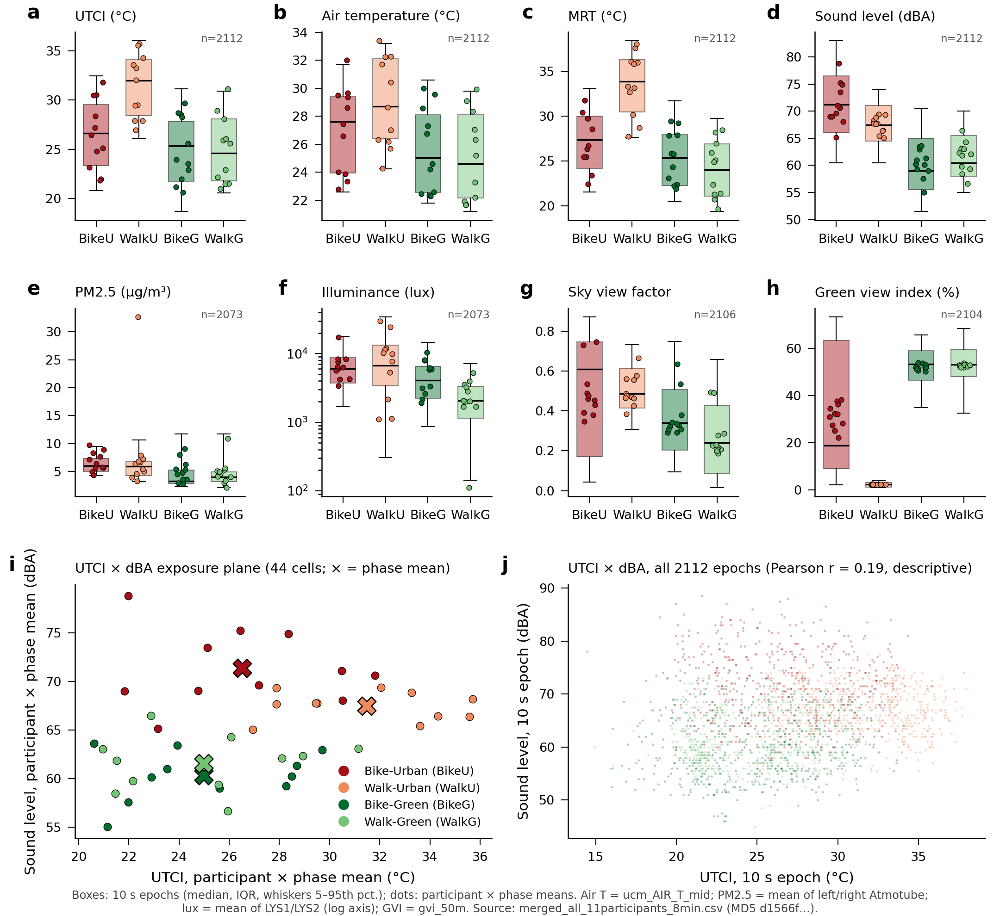

In [4]:
# Figure 3 — exposures by phase (10 s epochs) + UTCI × dBA plane (participant phase means)
EXPOSURES = [("ucm_UTCI", "UTCI (°C)", False), ("ucm_AIR_T_mid", "Air temperature (°C)", False),
             ("ucm_MRT", "MRT (°C)", False), ("ucm_SND_dBA", "Sound level (dBA)", False),
             ("atmo_pm2.5_avg", "PM2.5 (µg/m³)", False), ("lys_lux_avg", "Illuminance (lux)", True),
             ("SVF", "Sky view factor", False), ("gvi_50m", "Green view index (%)", False)]

def fig3():
    plot_data = merged()
    fig = plt.figure(figsize=(7.2, 6.6))
    gs = gridspec.GridSpec(3, 4, figure=fig, left=0.075, right=0.985, top=0.965, bottom=0.085, hspace=0.42, wspace=0.45,
                           height_ratios=[1, 1, 1.35])
    letters = "abcdefghij"
    pm = phase_means(plot_data, [e[0] for e in EXPOSURES])
    rng = np.random.default_rng(1)
    for index, (col, lab, logy) in enumerate(EXPOSURES):
        ax = fig.add_subplot(gs[index // 4, index % 4])
        vals = [plot_data.loc[plot_data.PhaseID == phase, col].astype(float).values for phase in PHASES]
        if logy: vals = [np.where(current_values > 0, current_values, np.nan) for current_values in vals]
        strip_box(ax, vals)
        for column_index, phase in enumerate(PHASES):
            y = pm.loc[pm.PhaseID == phase, col].values
            ax.scatter(column_index + rng.uniform(-0.17, 0.17, len(y)), y, s=7, color=PHASE_COL[phase], edgecolor="black", lw=0.3, zorder=3)
        if logy: ax.set_yscale("log")
        ax.set_xticks(range(4)); ax.set_xticklabels(PHASES, rotation=0)
        ax.set_title(lab, fontsize=7, loc="left")
        n_valid = int(np.isfinite(np.concatenate(vals)).sum())
        ax.text(0.99, 0.99, f"n={n_valid}", transform=ax.transAxes, ha="right", va="top", fontsize=5.5, color="#555555")
        panel_label(ax, letters[index], dx=-0.035)
    # UTCI x dBA plane
    ax = fig.add_subplot(gs[2, 0:2])
    for phase in PHASES:
        s = pm[pm.PhaseID == phase]
        ax.scatter(s.ucm_UTCI, s.ucm_SND_dBA, s=16, color=PHASE_COL[phase], edgecolor="black", lw=0.3, label=PHASE_LAB[phase], zorder=3)
        ax.scatter(s.ucm_UTCI.mean(), s.ucm_SND_dBA.mean(), s=90, marker="X", color=PHASE_COL[phase], edgecolor="black", lw=0.6, zorder=4)
    ax.set_xlabel("UTCI, participant × phase mean (°C)"); ax.set_ylabel("Sound level, participant × phase mean (dBA)")
    ax.set_title("UTCI × dBA exposure plane (44 cells; × = phase mean)", fontsize=7, loc="left")
    phase_legend(ax, loc="lower right", fontsize=6)
    panel_label(ax, "i", dx=-0.06)
    # within-bout (10 s) UTCI vs dBA, coloured by phase
    ax = fig.add_subplot(gs[2, 2:4])
    for phase in PHASES:
        s = plot_data[plot_data.PhaseID == phase]
        ax.scatter(s.ucm_UTCI, s.ucm_SND_dBA, s=1.2, color=PHASE_COL[phase], alpha=0.35, lw=0, rasterized=True)
    r = plot_data[["ucm_UTCI", "ucm_SND_dBA"]].corr().iloc[0, 1]
    ax.set_xlabel("UTCI, 10 s epoch (°C)"); ax.set_ylabel("Sound level, 10 s epoch (dBA)")
    ax.set_title(f"UTCI × dBA, all {len(plot_data)} epochs (Pearson r = {r:.2f}, descriptive)", fontsize=7, loc="left")
    panel_label(ax, "j", dx=-0.06)
    fig.text(0.5, 0.004, "Boxes: 10 s epochs (median, IQR, whiskers 5–95th pct.); dots: participant × phase means. Air T = ucm_AIR_T_mid; PM2.5 = mean of left/right Atmotube;\n"
             "lux = mean of LYS1/LYS2 (log axis); GVI = gvi_50m. Source: merged_all_11participants_8min.csv (MD5 d1566f…).",
             ha="center", fontsize=5.8, color="#444444")
    save(fig, "Figure3_exposures_by_phase")

fig3()

## Figure 4 — H1 + H3 forest plots (paired SMD, 26 outcomes)

Inputs (relative to `ROOT`):
* `output\statistical_analysis\results\H1_H3_phaseavg\H1_H3_Contrasts.csv` (H1 physiological rows)
* `output\statistical_analysis\results\H1_H3_phaseavg\H1_H3_Contrasts.csv` (H3 physiological rows)
* `output\statistical_analysis\Normalization & Parameter Screening\Normalization\Normalization_H1toH4_all_parameters.csv`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure4_H1_H3_forest.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure4_H1_H3_forest.pdf


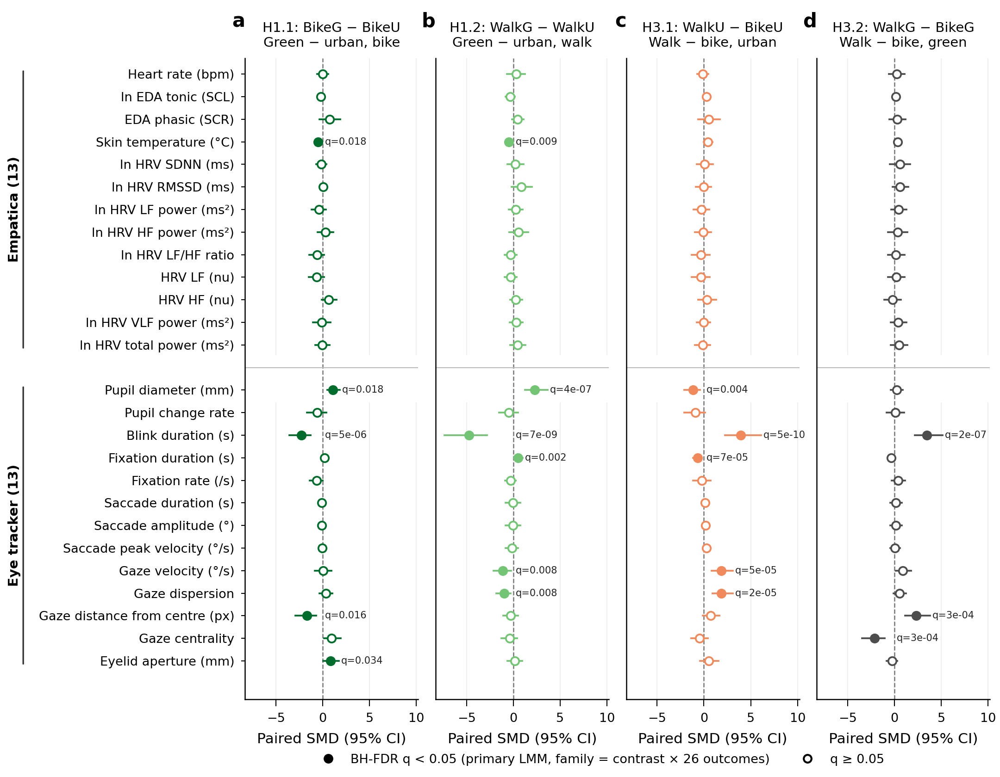

In [5]:
# Figure 4 — H1 + H3 forest plot (paired SMD, Bonett 2008; filled = primary-LMM BH q < 0.05)
def fig4():
    h1 = h1h3_contrasts("H1")
    h3 = h1h3_contrasts("H3")
    t = pd.concat([h1, h3]); t = t[t.normalization.str.startswith("Primary")]
    assert len(t) == 104 and set(t.adjustment_family_size) == {26}
    panels = [("H1.1", "BikeU_BikeG", "BikeG − BikeU", "Green − urban, bike", PHASE_COL["BikeG"]),
              ("H1.2", "WalkU_WalkG", "WalkG − WalkU", "Green − urban, walk", PHASE_COL["WalkG"]),
              ("H3.1", "BikeU_WalkU", "WalkU − BikeU", "Walk − bike, urban", PHASE_COL["WalkU"]),
              ("H3.2", "BikeG_WalkG", "WalkG − BikeG", "Walk − bike, green", "#4d4d4d")]
    ypos = {outcome: index + (1.0 if index >= 13 else 0) for index, outcome in enumerate(OUTCOMES)}
    fig = plt.figure(figsize=(7.2, 5.6))
    gs = gridspec.GridSpec(1, 4, figure=fig, left=0.245, right=0.99, top=0.925, bottom=0.10, wspace=0.10)
    xl = (np.floor(t.smd_ci_lower.min()) - 0.3, np.ceil(t.smd_ci_upper.max()) + 3.2)
    for key, (sub, con, lab, ttl, col) in enumerate(panels):
        ax = fig.add_subplot(gs[0, key]); s = t[(t.sub_hypothesis == sub) & (t.contrast == con)].set_index("outcome").reindex(OUTCOMES)
        assert s.smd.notna().sum() >= 25
        ax.axvline(0, color="#777777", lw=0.6, ls="--")
        ax.axhspan(12.5, 14.5, color="white")
        for outcome in OUTCOMES:
            r = s.loc[outcome]; y = ypos[outcome]
            if not np.isfinite(r.smd): continue
            sig = bool(r.significant_adjusted)
            ax.plot([r.smd_ci_lower, r.smd_ci_upper], [y, y], color=col, lw=0.9)
            ax.plot(r.smd, y, marker="o", ms=4.2, mfc=col if sig else "white", mec=col, mew=0.9)
            if sig: ax.text(max(r.smd_ci_upper, 0) + 0.25, y, f"q={r.p_value_adjusted:.3f}" if r.p_value_adjusted >= 0.001 else f"q={r.p_value_adjusted:.0e}", fontsize=5, ha="left", va="center", color="#222222")
        ax.set_ylim(27.7, -0.7); ax.set_xlim(*xl)
        ax.set_yticks([ypos[outcome] for outcome in OUTCOMES])
        ax.set_yticklabels([ulab(outcome) for outcome in OUTCOMES] if key == 0 else [])
        ax.tick_params(axis="y", length=0 if key else 2)
        ax.set_title(f"{sub}: {lab}\n{ttl}", fontsize=7, color="black")
        ax.set_xlabel("Paired SMD (95% CI)")
        ax.grid(axis="x", color="#eeeeee", lw=0.5); ax.set_axisbelow(True)
        panel_label(ax, "abcd"[key], dx=0.0, dy=0.035)
        if key == 0:
            for (y0, y1, txt) in [(0, 12, "Empatica (13)"), (14, 26, "Eye tracker (13)")]:
                ax.annotate("", xy=(-1.28, y0 - 0.3), xytext=(-1.28, y1 + 0.3), xycoords=ax.get_yaxis_transform(), textcoords=ax.get_yaxis_transform(),
                            arrowprops=dict(arrowstyle="-", lw=0.8, color="#333333"), annotation_clip=False)
                ax.text(-1.33, (y0 + y1) / 2, txt, transform=ax.get_yaxis_transform(), rotation=90, va="center", ha="center", fontsize=7, fontweight="bold")
        ax.axhline(13.0, color="#bbbbbb", lw=0.5)
    leg = [Line2D([], [], marker="o", ls="", mfc="black", mec="black", ms=4, label="BH-FDR q < 0.05 (primary LMM, family = contrast × 26 outcomes)"),
           Line2D([], [], marker="o", ls="", mfc="white", mec="black", ms=4, label="q ≥ 0.05")]
    fig.legend(handles=leg, loc="lower center", ncol=2, frameon=False, fontsize=6.5, bbox_to_anchor=(0.6, 0.0))
    save(fig, "Figure4_H1_H3_forest")

fig4()

## Figure 5 — H2 physiology × psychology rmcorr

Inputs (relative to `ROOT`):
* `output\statistical_analysis\results\H1_H3_phaseavg\H2_Concordance.csv` (test = H2_rmcorr_physio_psycho)
* `output\merged_all_11participants_8min.csv`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure5_H2_rmcorr.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure5_H2_rmcorr.pdf


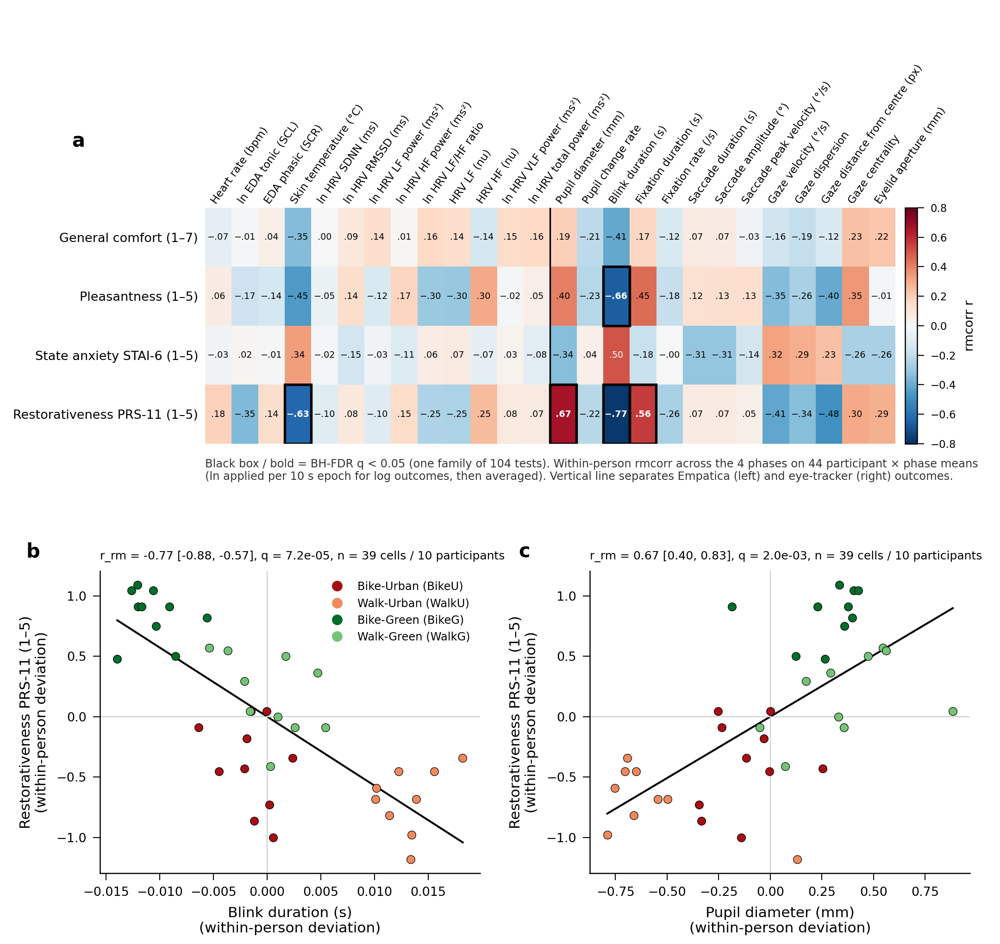

In [6]:
# Figure 5 — H2 rmcorr heatmap + two strongest surviving pairs
def rmcorr_fit(df, xcol, ycol):
    """lm(psych ~ factor(ParticipantID) + phys) as in H1_H3_core.R; returns r, slope, centred data."""
    x = df[["ParticipantID", xcol, ycol]].dropna()
    x = x[x.groupby("ParticipantID")[xcol].transform("size") >= 2]
    xc = x[xcol] - x.groupby("ParticipantID")[xcol].transform("mean")
    yc = x[ycol] - x.groupby("ParticipantID")[ycol].transform("mean")
    b = (xc * yc).sum() / (xc ** 2).sum()
    res = yc - b * xc; key = x.ParticipantID.nunique(); dfr = len(x) - key - 1
    se = np.sqrt((res ** 2).sum() / dfr / (xc ** 2).sum()); tv = b / se
    r = np.sign(tv) * np.sqrt(tv ** 2 / (tv ** 2 + dfr))
    return r, b, x.assign(xc=xc, yc=yc), dfr

def fig5():
    h2 = h2_concordance()
    assert len(h2) == 104
    R = h2.pivot(index="outcome", columns="term", values="correlation").reindex(index=SURVEYS, columns=OUTCOMES)
    Q = h2.pivot(index="outcome", columns="term", values="p_value_adjusted").reindex(index=SURVEYS, columns=OUTCOMES)
    fig = plt.figure(figsize=(7.2, 6.8))
    ax = fig.add_axes([0.205, 0.53, 0.69, 0.25])
    cmap = plt.get_cmap("RdBu_r")
    im = ax.imshow(R.values, cmap=cmap, vmin=-0.8, vmax=0.8, aspect="auto")
    for index in range(R.shape[0]):
        for column_index in range(R.shape[1]):
            current_values = R.values[index, column_index]; q = Q.values[index, column_index]
            if np.isfinite(current_values):
                ax.text(column_index, index, f"{current_values:.2f}".replace("0.", ".").replace("-.", "−."), ha="center", va="center", fontsize=4.6,
                        color="white" if abs(current_values) > 0.5 else "black", fontweight="bold" if q < 0.05 else "normal")
            if np.isfinite(q) and q < 0.05:
                ax.add_patch(Rectangle((column_index - 0.5, index - 0.5), 1, 1, fill=False, ec="black", lw=1.3))
    ax.set_yticks(range(4)); ax.set_yticklabels([SURVEY_LAB[s] for s in SURVEYS], fontsize=6.5)
    ax.set_xticks(range(26)); ax.set_xticklabels([ulab(outcome) for outcome in OUTCOMES], rotation=55, ha="left", rotation_mode="anchor", fontsize=5.6)
    ax.xaxis.tick_top(); ax.tick_params(axis="x", length=0, pad=1); ax.tick_params(axis="y", length=0)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.axvline(12.5, color="black", lw=0.8)
    cax = fig.add_axes([0.905, 0.53, 0.012, 0.25]); cb = fig.colorbar(im, cax=cax); cb.set_label("rmcorr r", fontsize=6.5); cb.ax.tick_params(labelsize=5.5)
    ax.text(-0.5, 3.75, "Black box / bold = BH-FDR q < 0.05 (one family of 104 tests). Within-person rmcorr across the 4 phases on 44 participant × phase means\n(ln applied per 10 s epoch for log outcomes, then averaged). Vertical line separates Empatica (left) and eye-tracker (right) outcomes.",
            fontsize=5.8, va="top", color="#333333")
    panel_label(ax, "a", dx=-0.12, dy=0.06)
    # strongest surviving pairs (smallest p among q<0.05)
    sig = h2[h2.significant_adjusted == True].sort_values("p_value").head(2)
    plot_data = analysis_units(merged()); pm = phase_means(plot_data, OUTCOMES + SURVEYS)
    for key, (_, row) in enumerate(sig.iterrows()):
        ax = fig.add_axes([0.1 + key * 0.49, 0.075, 0.38, 0.32])
        r, b, x, dfr = rmcorr_fit(pm, row.term, row.outcome)
        assert abs(r - row.correlation) < 1e-4 and abs(b - row.estimate) < 1e-4 * max(1, abs(b)), (r, row.correlation, b, row.estimate)
        x = x.merge(pm[["ParticipantID", "PhaseID", row.term, row.outcome]], on=["ParticipantID", row.term, row.outcome])
        for phase in PHASES:
            s = x[x.PhaseID == phase]; ax.scatter(s.xc, s.yc, s=18, color=PHASE_COL[phase], edgecolor="black", lw=0.3, zorder=3, label=PHASE_LAB[phase])
        xx = np.linspace(x.xc.min(), x.xc.max(), 10); ax.plot(xx, b * xx, color="black", lw=1)
        ax.axhline(0, color="#cccccc", lw=0.5); ax.axvline(0, color="#cccccc", lw=0.5)
        ax.set_xlabel(f"{ulab(row.term)}\n(within-person deviation)"); ax.set_ylabel(f"{SURVEY_LAB[row.outcome]}\n(within-person deviation)")
        ax.set_title(f"r_rm = {row.correlation:.2f} [{row.correlation_ci_lower:.2f}, {row.correlation_ci_upper:.2f}], q = {row.p_value_adjusted:.1e}, n = {row.n_observations} cells / {row.n_participants} participants",
                     fontsize=6, loc="left")
        if key == 0: phase_legend(ax, loc="upper right", fontsize=5.8)
        panel_label(ax, "bc"[key], dx=-0.06)
    save(fig, "Figure5_H2_rmcorr")

fig5()

## Figure 6 — H4 literature tests and the combined-exposure model

H4 uses `H4_sound_literature_test/SUMMARY_sound_tests_p_and_FDR.csv` (primary A-weighted sound). The heat maps use the combined-exposure exports. Those models are not the H4 test.


saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure6_H4_heat_noise.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure6_H4_heat_noise.pdf


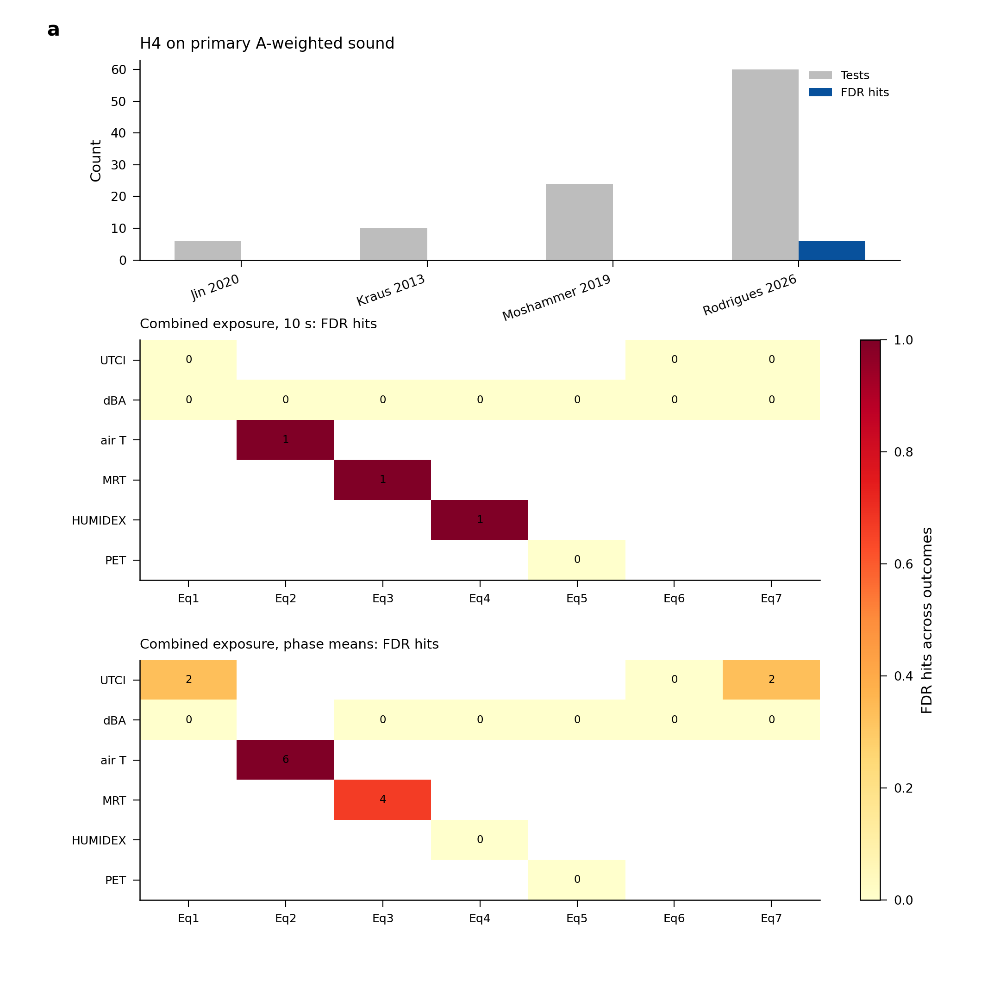

In [7]:
# Figure 6 — current H4 summary and combined-exposure coefficients
TERM_SHORT = {"ucm_UTCI": "UTCI", "ucm_SND_dBA": "dBA", "ucm_AIR_T_mid": "air T", "ucm_AIR_RH": "RH", "ucm_WIND_AWS": "wind",
              "ucm_MRT": "MRT", "ucm_HUMIDEX": "HUMIDEX", "ucm_PET": "PET"}

def fig6():
    h4 = _read_result_csv(src("res/H4/SUMMARY_sound_tests_p_and_FDR.csv", r"output\statistical_analysis\results\H4_sound_literature_test\SUMMARY_sound_tests_p_and_FDR.csv"))
    h4 = h4[h4.sound_variable.astype(str).str.contains("primary")].copy()
    h4["n_significant_adjusted"] = pd.to_numeric(h4["n_significant_adjusted"], errors="coerce").fillna(0)
    h4["n_tests"] = pd.to_numeric(h4["n_tests"], errors="coerce").fillna(0)
    by = h4.groupby("paper", as_index=False)[["n_tests", "n_significant_adjusted"]].sum()
    ts = _read_result_csv(src("res/Analysis_ts.csv", r"output\statistical_analysis\results\Analysis_combined_timeseries\Analysis_combined_timeseries_hypothesis.csv"))
    pa = _read_result_csv(src("res/Analysis_pa.csv", r"output\statistical_analysis\results\Analysis_combined_phaseavg\Analysis_combined_phaseavg_Heat_Noise_Exposures.csv"))
    keep = ["ucm_UTCI", "ucm_SND_dBA", "ucm_AIR_T_mid", "ucm_MRT", "ucm_HUMIDEX", "ucm_PET"]
    fig = plt.figure(figsize=(7.2, 7.2))
    ax = fig.add_axes([0.14, 0.74, 0.76, 0.20])
    x = np.arange(len(by))
    ax.bar(x - 0.18, by.n_tests, width=0.36, color="#bdbdbd", label="Tests")
    ax.bar(x + 0.18, by.n_significant_adjusted, width=0.36, color="#08519c", label="FDR hits")
    ax.set_xticks(x)
    ax.set_xticklabels(by.paper, rotation=20, ha="right")
    ax.set_ylabel("Count")
    ax.set_title("H4 on primary A-weighted sound", loc="left", fontsize=8)
    ax.legend(frameon=False, fontsize=6)
    panel_label(ax, "a", dx=-0.08, dy=0.02)

    def heat(tab, pos, letter, title):
        tab = tab[tab.term.isin(keep)].copy()
        tab["model_id"] = pd.to_numeric(tab["model_id"], errors="coerce")
        tab["q"] = pd.to_numeric(tab["p_value_adjusted"], errors="coerce")
        eqs = sorted(tab.model_id.dropna().unique())
        M = np.full((len(keep), len(eqs)), np.nan)
        for i, term in enumerate(keep):
            for j, eq in enumerate(eqs):
                sl = tab[(tab.term == term) & (tab.model_id == eq) & np.isfinite(tab.q)]
                if len(sl) == 0:
                    continue
                sig = sl[sl.significant_adjusted.astype(str).str.lower().isin(["true", "1"])]
                M[i, j] = len(sig)
        axh = fig.add_axes(pos)
        im = axh.imshow(M, cmap="YlOrRd", aspect="auto", vmin=0)
        axh.set_yticks(range(len(keep)))
        axh.set_yticklabels([TERM_SHORT.get(t, t) for t in keep], fontsize=6)
        axh.set_xticks(range(len(eqs)))
        axh.set_xticklabels(["Eq%d" % int(e) for e in eqs], fontsize=6)
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                if np.isfinite(M[i, j]):
                    axh.text(j, i, "%d" % int(M[i, j]), ha="center", va="center", fontsize=5.5)
        axh.set_title(title, loc="left", fontsize=7)
        panel_label(axh, letter, dx=-0.14, dy=0.02)
        return im

    im = heat(ts, [0.14, 0.42, 0.68, 0.24], "b", "Combined exposure, 10 s: FDR hits")
    heat(pa, [0.14, 0.10, 0.68, 0.24], "c", "Combined exposure, phase means: FDR hits")
    fig.colorbar(im, cax=fig.add_axes([0.86, 0.10, 0.02, 0.56]), label="FDR hits across outcomes")
    save(fig, "Figure6_H4_heat_noise")

fig6()


## Figure 7 — Sound composition by phase

Inputs (relative to `ROOT`):
* `output\merged_all_11participants_8min.csv`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure7_sound_composition.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\Figure7_sound_composition.pdf


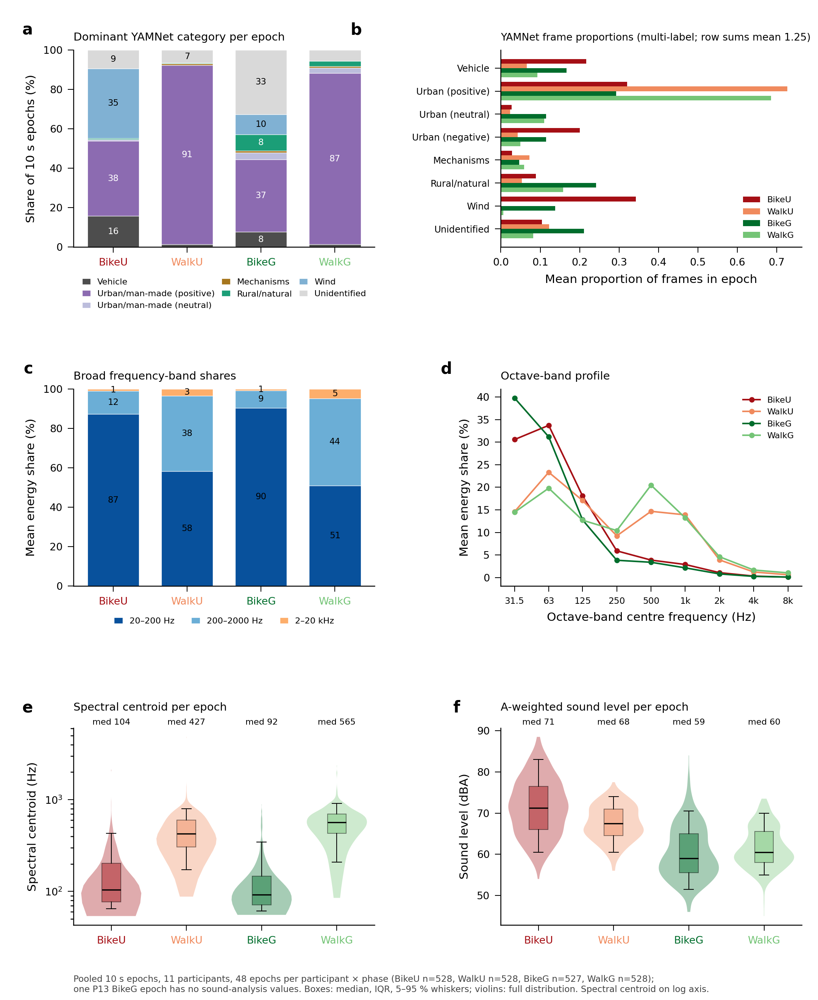

In [8]:
# Figure 7 — sound composition by phase (10 s epochs, 4 core phases)
YAM = [("vehicle_proportion", "Vehicle", "Vehicle"), ("urban_manmade_positive_proportion", "Urban/man-made (positive)", "Urban/Manmade_positive"),
       ("urban_manmade_neutral_proportion", "Urban/man-made (neutral)", "Urban/Manmade_neutral"),
       ("urban_manmade_negative_proportion", "Urban/man-made (negative)", "Urban/Manmade_negative"),
       ("mechanisms_proportion", "Mechanisms", "Mechanisms"), ("rural_natural_proportion", "Rural/natural", "Rural/Natural"),
       ("wind_proportion", "Wind", "Wind"), ("unidentify_proportion", "Unidentified", "Unidentify")]
YAM_COL = ["#4d4d4d", "#8c6bb1", "#bcbddc", "#e7298a", "#a6761d", "#1b9e77", "#80b1d3", "#d9d9d9"]

def fig7():
    plot_data = merged()
    fig = plt.figure(figsize=(7.2, 8.8))
    gs = fig.add_gridspec(3, 2, left=0.09, right=0.98, top=0.95, bottom=0.075, hspace=0.72, wspace=0.42)
    # a: dominant category per epoch
    ax = fig.add_subplot(gs[0, 0]); cats_present = set(plot_data["category"].dropna())
    assert cats_present <= {c for _, _, c in YAM}, cats_present
    bottom = np.zeros(4)
    for (col, lab, cat), cc in zip(YAM, YAM_COL):
        sh = np.array([(plot_data[plot_data.PhaseID == phase]["category"] == cat).sum() / plot_data[plot_data.PhaseID == phase]["category"].notna().sum() * 100 for phase in PHASES])
        if cat not in cats_present: continue
        ax.bar(range(4), sh, bottom=bottom, color=cc, edgecolor="white", lw=0.3, label=lab, width=0.7)
        for key in range(4):
            if sh[key] >= 6: ax.text(key, bottom[key] + sh[key] / 2, f"{sh[key]:.0f}", ha="center", va="center", fontsize=5.5, color="white" if cc in ("#4d4d4d", "#8c6bb1", "#1b9e77", "#a6761d") else "black")
        bottom += sh
    ax.set_xticks(range(4)); ax.set_xticklabels(PHASES); [tick_label.set_color(PHASE_COL[phase]) for tick_label, phase in zip(ax.get_xticklabels(), PHASES)]
    ax.set_ylabel("Share of 10 s epochs (%)"); ax.set_ylim(0, 100); ax.set_title("Dominant YAMNet category per epoch", fontsize=7, loc="left")
    ax.legend(frameon=False, fontsize=5.4, bbox_to_anchor=(0.5, -0.12), loc="upper center", ncol=3, handlelength=1, columnspacing=0.8)
    panel_label(ax, "a", dx=-0.05, dy=0.012)
    # b: mean YAMNet frame proportions (multi-label)
    ax = fig.add_subplot(gs[0, 1]); w = 0.2
    rows_sum = plot_data[[c for c, _, _ in YAM]].sum(axis=1, min_count=1)
    for key, phase in enumerate(PHASES):
        m = plot_data[plot_data.PhaseID == phase][[c for c, _, _ in YAM]].mean()
        ax.barh(np.arange(len(YAM)) + (key - 1.5) * w, m.values, height=w, color=PHASE_COL[phase], label=phase)
    ax.set_yticks(range(len(YAM))); ax.set_yticklabels([l.replace("Urban/man-made", "Urban") for _, l, _ in YAM], fontsize=5.8); ax.invert_yaxis()
    ax.set_xlabel("Mean proportion of frames in epoch")
    ax.set_title(f"YAMNet frame proportions (multi-label; row sums mean {rows_sum.mean():.2f})", fontsize=6.4, loc="left")
    ax.legend(frameon=False, fontsize=5.4, loc="lower right")
    panel_label(ax, "b", dx=-0.17, dy=0.012)
    # c: three broad frequency bands
    ax = fig.add_subplot(gs[1, 0]); bands = [("freq_proportion_20_to_200Hz", "20–200 Hz", "#08519c"), ("freq_proportion_200_to_2000Hz", "200–2000 Hz", "#6baed6"), ("freq_proportion_2000_to_20000Hz", "2–20 kHz", "#fdae6b")]
    bottom = np.zeros(4)
    for col, lab, cc in bands:
        m = np.array([plot_data[plot_data.PhaseID == phase][col].mean() * 100 for phase in PHASES])
        ax.bar(range(4), m, bottom=bottom, color=cc, edgecolor="white", lw=0.3, width=0.7, label=lab)
        for key in range(4): ax.text(key, bottom[key] + m[key] / 2, f"{m[key]:.0f}", ha="center", va="center", fontsize=5.5)
        bottom += m
    ax.set_xticks(range(4)); ax.set_xticklabels(PHASES); [tick_label.set_color(PHASE_COL[phase]) for tick_label, phase in zip(ax.get_xticklabels(), PHASES)]
    ax.set_ylim(0, 100); ax.set_ylabel("Mean energy share (%)"); ax.set_title("Broad frequency-band shares", fontsize=7, loc="left")
    ax.legend(frameon=False, fontsize=5.4, bbox_to_anchor=(0.5, -0.12), loc="upper center", ncol=3, handlelength=1)
    panel_label(ax, "c", dx=-0.05, dy=0.012)
    # d: octave-band profile
    ax = fig.add_subplot(gs[1, 1]); oc = [c for c in plot_data.columns if c.startswith("octave_proportion_")]
    fc = [float(c.replace("octave_proportion_", "").replace("_Hz", "").replace("_", ".")) for c in oc]
    for phase in PHASES:
        x = plot_data[plot_data.PhaseID == phase][oc]; m = x.mean(); s = x.std(ddof=1) / np.sqrt(x.notna().sum())
        ax.plot(fc, m.values * 100, "-o", color=PHASE_COL[phase], ms=2.5, lw=1, label=phase)
    ax.set_xscale("log"); ax.set_xticks(fc); ax.set_xticklabels([("%g" % f) if f < 1000 else ("%gk" % (f / 1000)) for f in fc], fontsize=5.6)
    ax.minorticks_off(); ax.set_xlabel("Octave-band centre frequency (Hz)"); ax.set_ylabel("Mean energy share (%)")
    ax.set_title("Octave-band profile", fontsize=7, loc="left"); ax.legend(frameon=False, fontsize=5.4)
    panel_label(ax, "d", dx=-0.06, dy=0.012)
    # e: spectral centroid; f: dBA
    for g, col, lab, ttl, lt in [(gs[2, 0], "spectral_centroid_Hz", "Spectral centroid (Hz)", "Spectral centroid per epoch", "e"),
                                 (gs[2, 1], "ucm_SND_dBA", "Sound level (dBA)", "A-weighted sound level per epoch", "f")]:
        ax = fig.add_subplot(g)
        vals = [plot_data[plot_data.PhaseID == phase][col].astype(float).values for phase in PHASES]
        vp = ax.violinplot([current_values[np.isfinite(current_values)] for current_values in vals], positions=range(4), widths=0.8, showextrema=False)
        for b, phase in zip(vp["bodies"], PHASES): b.set_facecolor(PHASE_COL[phase]); b.set_alpha(0.35); b.set_edgecolor("none")
        strip_box(ax, vals, width=0.25)
        for key, current_values in enumerate(vals): ax.text(key, 1.01, f"med {np.nanmedian(current_values):.0f}", transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=5.4)
        ax.set_xticks(range(4)); ax.set_xticklabels(PHASES); [tick_label.set_color(PHASE_COL[phase]) for tick_label, phase in zip(ax.get_xticklabels(), PHASES)]
        if col == "spectral_centroid_Hz": ax.set_yscale("log")
        ax.set_ylabel(lab); ax.set_title(ttl, fontsize=7, loc="left", pad=11)
        panel_label(ax, lt, dx=-0.05, dy=0.012)
    n = {phase: int(plot_data[plot_data.PhaseID == phase]["category"].notna().sum()) for phase in PHASES}
    fig.text(0.09, 0.008, "Pooled 10 s epochs, 11 participants, 48 epochs per participant × phase (" + ", ".join(f"{phase} n={n[phase]}" for phase in PHASES) +
             ");\none P13 BikeG epoch has no sound-analysis values. Boxes: median, IQR, 5–95 % whiskers; violins: full distribution. Spectral centroid on log axis.", fontsize=5.6, color="#444444")
    save(fig, "Figure7_sound_composition")

fig7()

## Figure S1 — Participants and data coverage

Inputs (relative to `ROOT`):
* `Figures\manuscript_figures\Participants matched_8min.png`
* `output\merged_all_11participants_8min.csv`

S1 coverage min outcome 0.0 min exposure 87.5


saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS1_participants_coverage.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS1_participants_coverage.pdf


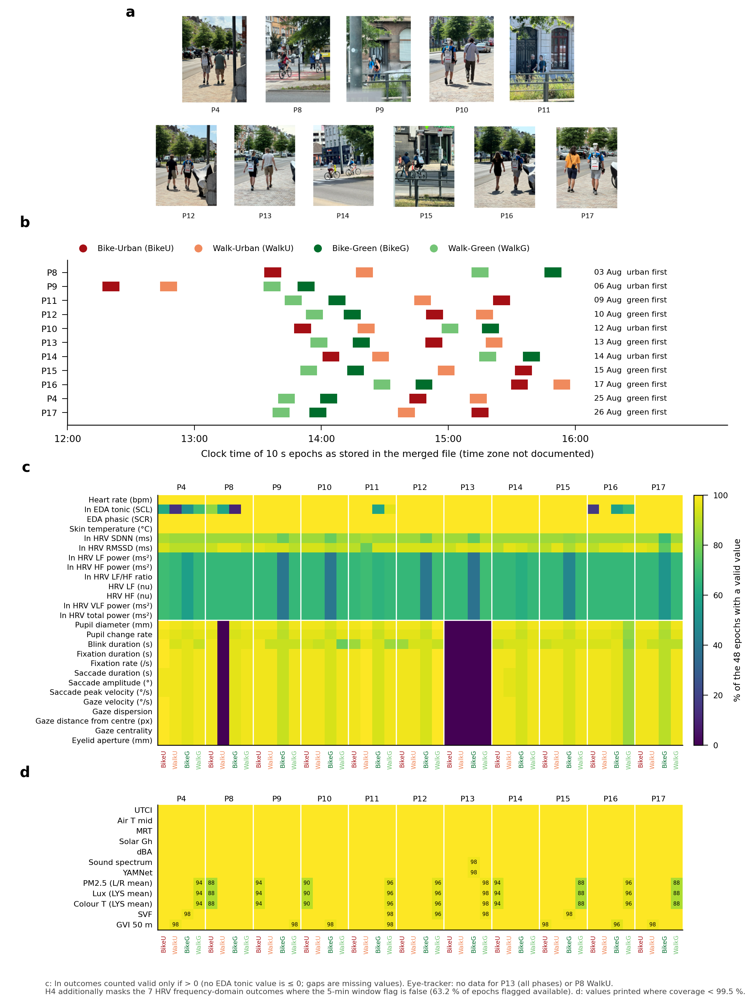

In [9]:
# Figure S1 — participants and data coverage
def figS1():
    plot_data = merged(); a = analysis_units(plot_data)
    photos = src("art/Participants matched_8min.png", r"Figures\manuscript_figures\Participants matched_8min.png")
    fig = plt.figure(figsize=(7.2, 9.6))
    axa = fig.add_axes([0.06, 0.775, 0.90, 0.215]); img_axes(axa, photos); panel_label(axa, "a", dx=-0.01, dy=-0.01)
    # b: session timeline
    axb = fig.add_axes([0.09, 0.575, 0.88, 0.165])
    order = sorted(PARTICIPANTS, key=lambda participant_id: plot_data[plot_data.ParticipantID == participant_id].Datetime.min().date())
    for index, pid in enumerate(order):
        x = plot_data[plot_data.ParticipantID == pid]; day = x.Datetime.min().normalize()
        for ph in PHASES:
            y = x[x.PhaseID == ph]; t0 = (y.Datetime.min() - day).total_seconds() / 3600; t1 = (y.Datetime.max() - day).total_seconds() / 3600 + 10 / 3600
            axb.barh(index, t1 - t0, left=t0, color=PHASE_COL[ph], height=0.7)
        first = x.sort_values("Datetime").PhaseID.iloc[0]
        axb.text(16.15, index, x.Datetime.min().strftime("%d %b") + ("  green first" if first in ("BikeG", "WalkG") else "  urban first"), va="center", fontsize=5.4)
    axb.set_yticks(range(len(order))); axb.set_yticklabels(order, fontsize=6); axb.invert_yaxis()
    axb.set_xlim(12, 17.2); axb.set_xticks(range(12, 17)); axb.set_xticklabels([f"{h}:00" for h in range(12, 17)])
    axb.set_xlabel("Clock time of 10 s epochs as stored in the merged file (time zone not documented)", fontsize=6.5)
    phase_legend(axb, loc="lower left", ncol=4, fontsize=5.6, bbox_to_anchor=(0.0, 1.0))
    panel_label(axb, "b", dx=-0.05, dy=0.03)
    # c: outcome coverage
    cells = [(participant_id, ph) for participant_id in PARTICIPANTS for ph in PHASES]
    C = np.array([[a[(a.ParticipantID == participant_id) & (a.PhaseID == ph)][outcome].astype(float).notna().mean() * 100 for participant_id, ph in cells] for outcome in OUTCOMES])
    axc = fig.add_axes([0.21, 0.255, 0.70, 0.25])
    im = axc.imshow(C, cmap="viridis", vmin=0, vmax=100, aspect="auto", interpolation="nearest")
    axc.set_yticks(range(26)); axc.set_yticklabels([ulab(outcome) for outcome in OUTCOMES], fontsize=5.2)
    axc.set_xticks(range(len(cells))); axc.set_xticklabels([ph for _, ph in cells], rotation=90, fontsize=4.2)
    for t, (_, ph) in zip(axc.get_xticklabels(), cells): t.set_color(PHASE_COL[ph])
    for key, participant_id in enumerate(PARTICIPANTS):
        axc.text(key * 4 + 1.5, -0.9, participant_id, ha="center", va="bottom", fontsize=5.4)
        if key: axc.axvline(key * 4 - 0.5, color="white", lw=0.8)
    axc.axhline(12.5, color="white", lw=0.8); axc.tick_params(length=0)
    cb = fig.colorbar(im, cax=fig.add_axes([0.925, 0.255, 0.012, 0.25])); cb.set_label("% of the 48 epochs with a valid value", fontsize=6); cb.ax.tick_params(labelsize=5.5)
    panel_label(axc, "c", dx=-0.17, dy=0.02)
    # d: exposure coverage
    expo = [("ucm_UTCI", "UTCI"), ("ucm_AIR_T_mid", "Air T mid"), ("ucm_MRT", "MRT"), ("ucm_SUN_Gh", "Solar Gh"), ("ucm_SND_dBA", "dBA"),
            ("spectral_centroid_Hz", "Sound spectrum"), ("vehicle_proportion", "YAMNet"), ("atmo_pm2.5_avg", "PM2.5 (L/R mean)"),
            ("lys_lux_avg", "Lux (LYS mean)"), ("lys_kelvin_avg", "Colour T (LYS mean)"), ("SVF", "SVF"), ("gvi_50m", "GVI 50 m")]
    E = np.array([[plot_data[(plot_data.ParticipantID == participant_id) & (plot_data.PhaseID == ph)][c].astype(float).notna().mean() * 100 for participant_id, ph in cells] for c, _ in expo])
    axd = fig.add_axes([0.21, 0.07, 0.70, 0.125])
    axd.imshow(E, cmap="viridis", vmin=0, vmax=100, aspect="auto", interpolation="nearest")
    axd.set_yticks(range(len(expo))); axd.set_yticklabels([l for _, l in expo], fontsize=5.4)
    axd.set_xticks(range(len(cells))); axd.set_xticklabels([ph for _, ph in cells], rotation=90, fontsize=4.2)
    for t, (_, ph) in zip(axd.get_xticklabels(), cells): t.set_color(PHASE_COL[ph])
    for key, participant_id in enumerate(PARTICIPANTS):
        axd.text(key * 4 + 1.5, -0.7, participant_id, ha="center", va="bottom", fontsize=5.4)
        if key: axd.axvline(key * 4 - 0.5, color="white", lw=0.8)
    axd.tick_params(length=0)
    for index in range(len(expo)):
        for column_index in range(len(cells)):
            if E[index, column_index] < 99.5: axd.text(column_index, index, f"{E[index, column_index]:.0f}", ha="center", va="center", fontsize=3.6, color="white" if E[index, column_index] < 60 else "black")
    panel_label(axd, "d", dx=-0.17, dy=0.025)
    hrv_av = (plot_data["empatica_hrv_fd_5min_available"].astype(str).str.lower().isin(["true", "1"])).mean() * 100
    fig.text(0.06, 0.006, f"c: ln outcomes counted valid only if > 0 (no EDA tonic value is ≤ 0; gaps are missing values). Eye-tracker: no data for P13 (all phases) or P8 WalkU.\nH4 additionally masks the 7 HRV frequency-domain outcomes where the 5-min window flag is false ({hrv_av:.1f} % of epochs flagged available). d: values printed where coverage < 99.5 %.",
             fontsize=5.3, color="#444444")
    print("S1 coverage min outcome", np.nanmin(C), "min exposure", np.nanmin(E))
    save(fig, "Figure8_participants_coverage")

figS1()

## Figure S2 — 26 outcomes by phase (participant × phase means)

Inputs (relative to `ROOT`):
* `output\merged_all_11participants_8min.csv`
* `output\statistical_analysis\results\H1_H3_phaseavg\H1_H3_Contrasts.csv` (H1 and H3 physiological rows)

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS2_outcomes_by_phase.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS2_outcomes_by_phase.pdf


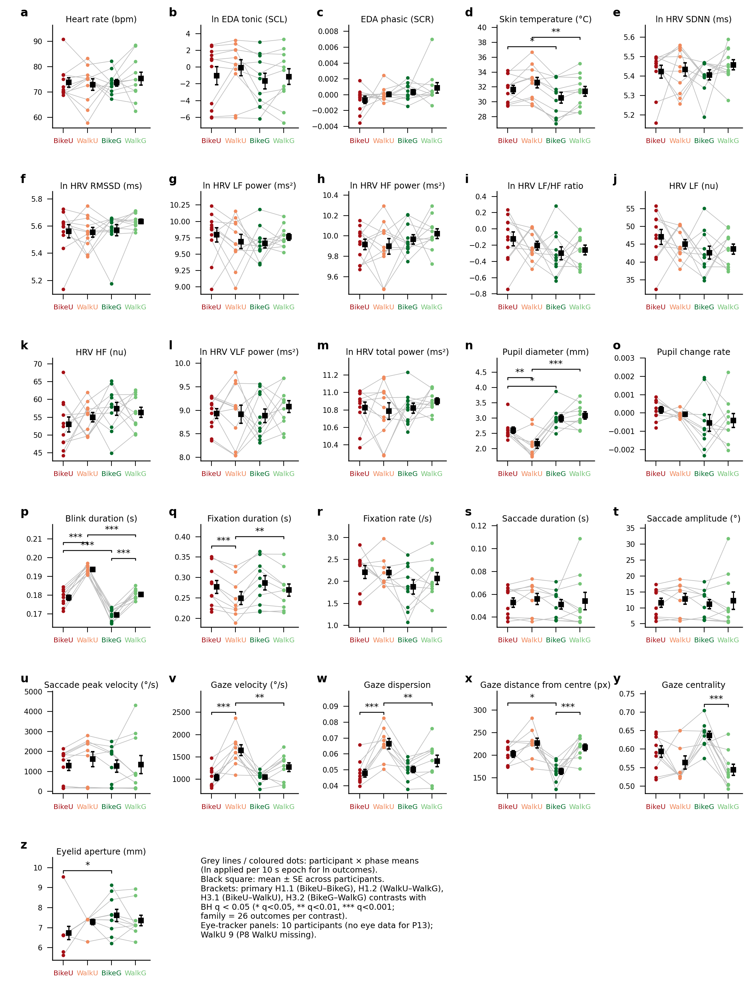

In [10]:
# Figure S2 — 26 outcomes by phase (participant × phase means, analysis units)
def figS2():
    plot_data = analysis_units(merged()); pm = phase_means(plot_data, OUTCOMES)
    h1 = h1h3_contrasts("H1")
    h3 = h1h3_contrasts("H3")
    t = pd.concat([h1, h3]); t = t[t.normalization.str.startswith("Primary")]
    pos = {phase: index for index, phase in enumerate(PHASES)}
    fig, axes = plt.subplots(6, 5, figsize=(7.2, 9.6))
    fig.subplots_adjust(left=0.07, right=0.99, top=0.975, bottom=0.04, hspace=0.62, wspace=0.52)
    letters = "abcdefghijklmnopqrstuvwxyz"
    for key, outcome in enumerate(OUTCOMES):
        ax = axes.flat[key]
        w = pm.pivot(index="ParticipantID", columns="PhaseID", values=outcome).reindex(columns=PHASES)
        for pid, r in w.iterrows(): ax.plot(range(4), r.values, color="#bbbbbb", lw=0.4, zorder=1)
        for phase in PHASES:
            current_values = w[phase].dropna().values
            ax.scatter(np.full(len(current_values), pos[phase]), current_values, s=6, color=PHASE_COL[phase], zorder=2, lw=0)
            ax.errorbar(pos[phase] + 0.22, current_values.mean(), yerr=current_values.std(ddof=1) / np.sqrt(len(current_values)), fmt="s", ms=2.8, color="black", lw=0.7, capsize=1.2, zorder=3)
        for _, r in t[t.outcome == outcome].iterrows():   # assert means agree with the exported contrast table
            assert abs(w[r.reference_phase_id].mean() - r.reference_mean_raw) <= 1e-6 * max(1, abs(r.reference_mean_raw))
        sig = t[(t.outcome == outcome) & (t.significant_adjusted.astype(str).str.upper() == "TRUE")]
        lo, hi = np.nanmin(w.values), np.nanmax(w.values); rng = hi - lo if hi > lo else 1; lev = 0
        for _, r in sig.sort_values("contrast").iterrows():
            a_, b_ = sorted([pos[r.reference_phase_id], pos[r.comparison_phase_id]]); y = hi + rng * (0.08 + 0.13 * lev)
            ax.plot([a_, a_, b_, b_], [y - rng * 0.03, y, y, y - rng * 0.03], color="black", lw=0.6)
            ax.text((a_ + b_) / 2, y, "*" if r.p_value_adjusted >= 0.01 else ("**" if r.p_value_adjusted >= 0.001 else "***"), ha="center", va="bottom", fontsize=6.5, linespacing=0.6)
            lev += 1
        ax.set_ylim(lo - rng * 0.06, hi + rng * (0.12 + 0.13 * max(lev, 0.4)))
        ax.set_xticks(range(4)); ax.set_xticklabels(PHASES, fontsize=4.8, rotation=0)
        for tl, phase in zip(ax.get_xticklabels(), PHASES): tl.set_color(PHASE_COL[phase])
        ax.tick_params(axis="y", labelsize=5); ax.set_xlim(-0.45, 3.6)
        ax.set_title(ulab(outcome), fontsize=5.8, pad=2)
        ax.text(-0.33, 1.06, letters[key], transform=ax.transAxes, fontsize=8, fontweight="bold", va="bottom")
    for ax in axes.flat[26:]: ax.set_axis_off()
    axl = axes.flat[26]
    txt = ("Grey lines / coloured dots: participant × phase means\n(ln applied per 10 s epoch for ln outcomes).\n"
           "Black square: mean ± SE across participants.\n"
           "Brackets: primary H1.1 (BikeU–BikeG), H1.2 (WalkU–WalkG),\nH3.1 (BikeU–WalkU), H3.2 (BikeG–WalkG) contrasts with\n"
           "BH q < 0.05 (* q<0.05, ** q<0.01, *** q<0.001;\nfamily = 26 outcomes per contrast).\n"
           "Eye-tracker panels: 10 participants (no eye data for P13);\nWalkU 9 (P8 WalkU missing).")
    axl.text(0.0, 1.0, txt, transform=axl.transAxes, fontsize=5.6, va="top")
    save(fig, "Figure9_outcomes_by_phase")

figS2()

## Figure S3 — Example 10 s traces (P10, all four phases)

Inputs (relative to `ROOT`):
* `output\merged_all_11participants_8min.csv`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS3_example_traces.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS3_example_traces.pdf


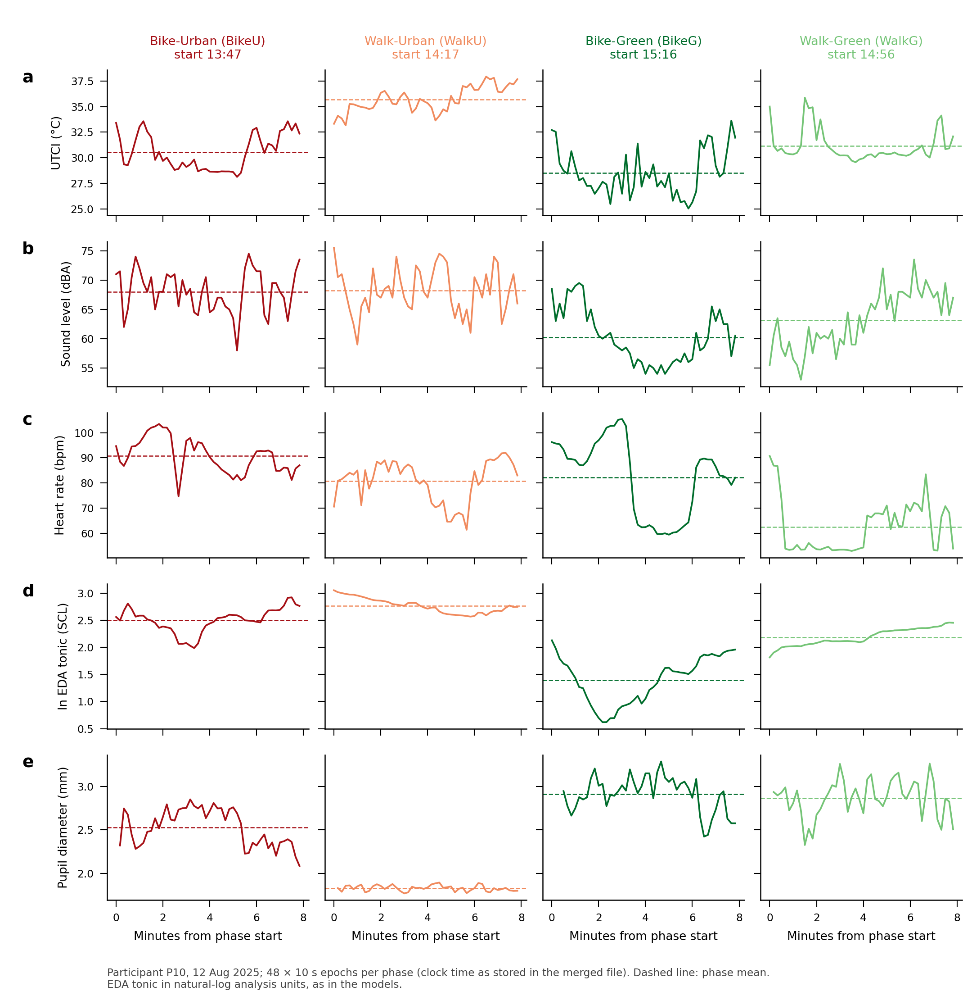

In [11]:
# Figure S3 — example 10 s traces (one participant, all four phases)
def figS3(pid="P10"):
    plot_data = analysis_units(merged()); x = plot_data[plot_data.ParticipantID == pid]
    vars_ = [("ucm_UTCI", "UTCI (°C)"), ("ucm_SND_dBA", "Sound level (dBA)"), ("empatica_heart_rate", ulab("empatica_heart_rate")),
             ("empatica_eda_tonic", ulab("empatica_eda_tonic")), ("eyetracker_pupil_diameter_avg", ulab("eyetracker_pupil_diameter_avg"))]
    for current_values, _ in vars_: assert x[current_values].notna().mean() > 0.9, (current_values, x[current_values].notna().mean())
    fig, axes = plt.subplots(len(vars_), 4, figsize=(7.2, 7.4), sharey="row", sharex=True)
    fig.subplots_adjust(left=0.11, right=0.99, top=0.93, bottom=0.1, hspace=0.18, wspace=0.08)
    starts = {phase: x[x.PhaseID == phase].Datetime.min() for phase in PHASES}
    for index, (current_values, lab) in enumerate(vars_):
        for column_index, phase in enumerate(PHASES):
            ax = axes[index, column_index]; y = x[x.PhaseID == phase]
            ax.plot(y.t_sec / 60, y[current_values].astype(float), color=PHASE_COL[phase], lw=0.9)
            m = y[current_values].astype(float).mean(); ax.axhline(m, color=PHASE_COL[phase], lw=0.6, ls="--")
            if index == 0: ax.set_title(f"{PHASE_LAB[phase]} ({phase})\nstart {starts[phase].strftime('%H:%M')}", fontsize=6.5, color=PHASE_COL[phase])
            if column_index == 0: ax.set_ylabel(lab, fontsize=6.3)
            if index == len(vars_) - 1: ax.set_xlabel("Minutes from phase start", fontsize=6.3)
            ax.tick_params(labelsize=5.6)
        axes[index, 0].text(-0.42, 1.0, "abcde"[index], transform=axes[index, 0].transAxes, fontsize=9, fontweight="bold", va="top")
    fig.text(0.11, 0.012, f"Participant {pid}, {x.Datetime.min().strftime('%d %b %Y')}; 48 × 10 s epochs per phase (clock time as stored in the merged file). Dashed line: phase mean.\n"
             "EDA tonic in natural-log analysis units, as in the models.", fontsize=5.6, color="#444444")
    save(fig, "Figure10_example_traces")

figS3()

## Figure S4 — H5 corridor-cell results

Inputs: `H5_exploratory/H5_RH1_hotspot_FDR_all_tests.csv` and `H5_epoch_hotspot_assignment.csv`.


saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS4_H5_hotspots.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS4_H5_hotspots.pdf


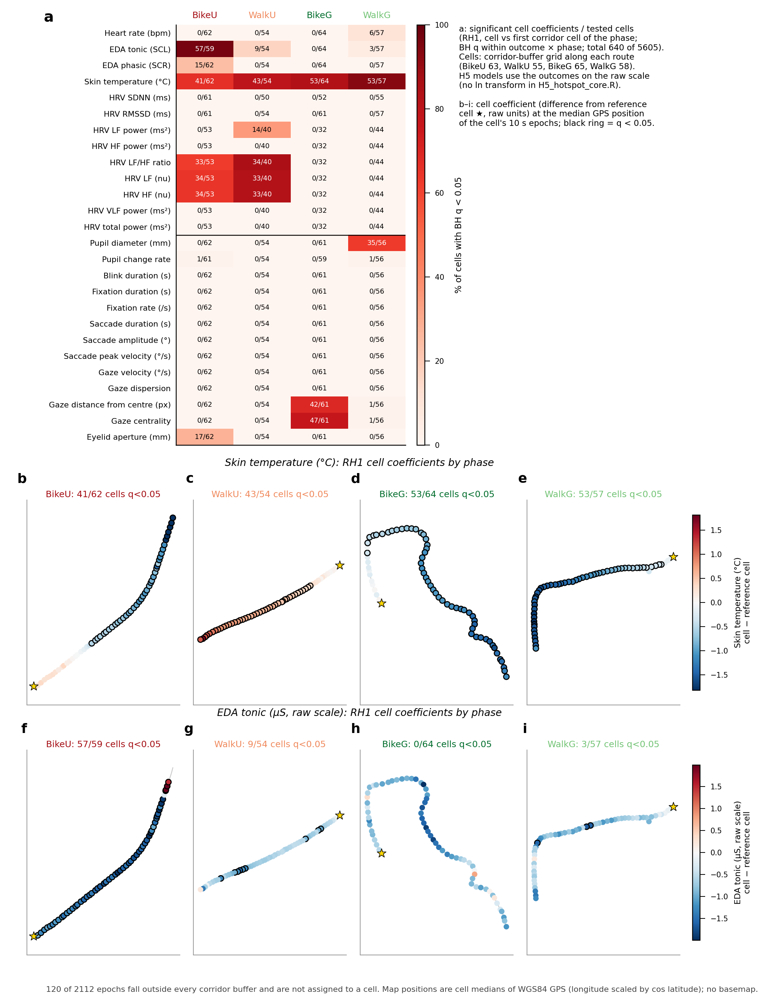

In [12]:
# Figure S4 — H5 corridor-cell (hotspot) results
def figS4():
    grid_results = _read_result_csv(src("res/H5/H5_RH1_hotspot_FDR_all_tests.csv", r"output\statistical_analysis\results\H5_exploratory\H5_RH1_hotspot_FDR_all_tests.csv"))
    ea = _read_result_csv(src("res/H5/H5_epoch_hotspot_assignment.csv", r"output\statistical_analysis\results\H5_exploratory\H5_epoch_hotspot_assignment.csv"))
    # grid-label table (former H5_corridor_grid_label_map.csv) = one row per corridor cell of the merged epoch table
    gm = ea.dropna(subset=["grid_label"])[["phase_id", "hotspot_id", "route_bin", "buffer_seg_idx", "grid_number", "grid_label"]].drop_duplicates().sort_values(["phase_id", "grid_number"]).reset_index(drop=True)
    # verify the stored FDR = BH within outcome x phase
    for (outcome, phase), grid_group in grid_results.groupby(["outcome", "phase_id"]):
        assert np.allclose(bh(grid_group.p_value.values), grid_group.p_value_adjusted.values, atol=1e-9, equal_nan=True)
    cen = ea.dropna(subset=["hotspot_id"]).groupby("hotspot_id")[["ucm_GPS_lat", "ucm_GPS_lon"]].median()
    fig = plt.figure(figsize=(7.2, 9.4))
    # a: count heatmap
    axa = fig.add_axes([0.23, 0.555, 0.30, 0.42])
    N = grid_results.groupby(["outcome", "phase_id"]).size().unstack().reindex(index=OUTCOMES, columns=PHASES)
    S = grid_results[grid_results.p_value_adjusted < 0.05].groupby(["outcome", "phase_id"]).size().unstack().reindex(index=OUTCOMES, columns=PHASES).fillna(0)
    im = axa.imshow((S / N * 100).values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
    for index in range(26):
        for column_index in range(4):
            current_values = S.values[index, column_index] / N.values[index, column_index] * 100
            axa.text(column_index, index, f"{int(S.values[index, column_index])}/{int(N.values[index, column_index])}", ha="center", va="center", fontsize=4.6, color="white" if current_values > 60 else "black")
    axa.set_yticks(range(26)); axa.set_yticklabels([LAB[outcome] for outcome in OUTCOMES], fontsize=5.3)
    axa.set_xticks(range(4)); axa.set_xticklabels(PHASES, fontsize=6); axa.xaxis.tick_top(); axa.tick_params(length=0)
    for tl, phase in zip(axa.get_xticklabels(), PHASES): tl.set_color(PHASE_COL[phase])
    axa.axhline(12.5, color="black", lw=0.6)
    cb = fig.colorbar(im, cax=fig.add_axes([0.545, 0.555, 0.01, 0.42])); cb.set_label("% of cells with BH q < 0.05", fontsize=5.8); cb.ax.tick_params(labelsize=5)
    panel_label(axa, "a", dx=-0.16, dy=0.0)
    fig.text(0.6, 0.975, f"a: significant cell coefficients / tested cells\n(RH1, cell vs first corridor cell of the phase;\nBH q within outcome × phase; total {int(S.values.sum())} of {len(grid_results)}).\n"
             f"Cells: corridor-buffer grid along each route\n({', '.join(f'{phase} {int((gm.phase_id == phase).sum())}' for phase in PHASES)}).\n"
             "H5 models use the outcomes on the raw scale\n(no ln transform in H5_hotspot_core.R).\n\n"
             "b–i: cell coefficient (difference from reference\ncell ★, raw units) at the median GPS position\nof the cell's 10 s epochs; black ring = q < 0.05.",
             fontsize=5.6, va="top")
    # maps
    lat0 = ea.ucm_GPS_lat.median(); kx = np.cos(np.deg2rad(lat0))
    rows = [("empatica_skin_temperature", "Skin temperature (°C)", "bcde"), ("empatica_eda_tonic", "EDA tonic (µS, raw scale)", "fghi")]
    for r, (outcome, lab, lets) in enumerate(rows):
        s = grid_results[grid_results.outcome == outcome]; vmax = np.nanpercentile(np.abs(s.estimate), 98)
        for column_index, phase in enumerate(PHASES):
            ax = fig.add_axes([0.035 + column_index * 0.218, 0.295 - r * 0.25, 0.2, 0.205])
            grid_group = gm[gm.phase_id == phase].merge(s[s.phase_id == phase][["grid_label", "estimate", "p_value_adjusted"]], on="grid_label", how="left")
            grid_group = grid_group.join(cen, on="hotspot_id")
            ref = grid_group[grid_group.grid_number == 1]
            ax.plot(grid_group.sort_values("route_bin").ucm_GPS_lon * kx, grid_group.sort_values("route_bin").ucm_GPS_lat, color="#cccccc", lw=0.6, zorder=1)
            sc = ax.scatter(grid_group.ucm_GPS_lon * kx, grid_group.ucm_GPS_lat, c=grid_group.estimate, cmap="RdBu_r", vmin=-vmax, vmax=vmax, s=14, zorder=2,
                            edgecolors=np.where(grid_group.p_value_adjusted < 0.05, "black", "none"), linewidths=0.7)
            ax.scatter(ref.ucm_GPS_lon * kx, ref.ucm_GPS_lat, marker="*", s=40, color="gold", edgecolors="black", linewidths=0.4, zorder=3)
            ax.set_aspect("equal", adjustable="datalim"); ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values(): sp.set_color("#999999"); sp.set_linewidth(0.5)
            ns = int((grid_group.p_value_adjusted < 0.05).sum()); nt = int(grid_group.estimate.notna().sum())
            ax.set_title(f"{phase}: {ns}/{nt} cells q<0.05", fontsize=6, color=PHASE_COL[phase], pad=2)
            ax.text(0.0, 1.07, lets[column_index], transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")
        cax = fig.add_axes([0.905, 0.31 - r * 0.25, 0.01, 0.175]); cb = fig.colorbar(sc, cax=cax)
        cb.set_label(f"{lab}\ncell − reference cell", fontsize=5.6); cb.ax.tick_params(labelsize=5)
        fig.text(0.47, 0.532 - r * 0.25, lab + ": RH1 cell coefficients by phase", fontsize=6.8, ha="center", va="bottom", style="italic")
    fig.text(0.06, 0.008, f"{int(ea.hotspot_id.isna().sum())} of {len(ea)} epochs fall outside every corridor buffer and are not assigned to a cell. "
             "Map positions are cell medians of WGS84 GPS (longitude scaled by cos latitude); no basemap.", fontsize=5.4, color="#444444")
    save(fig, "Figure11_H5_hotspots")

figS4()

## Figure S5 — H6 composite concordance

Only the current `H6_stress_composite` exports. Retired tables are not read.


saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS5_supplementary_H6.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS5_supplementary_H6.pdf


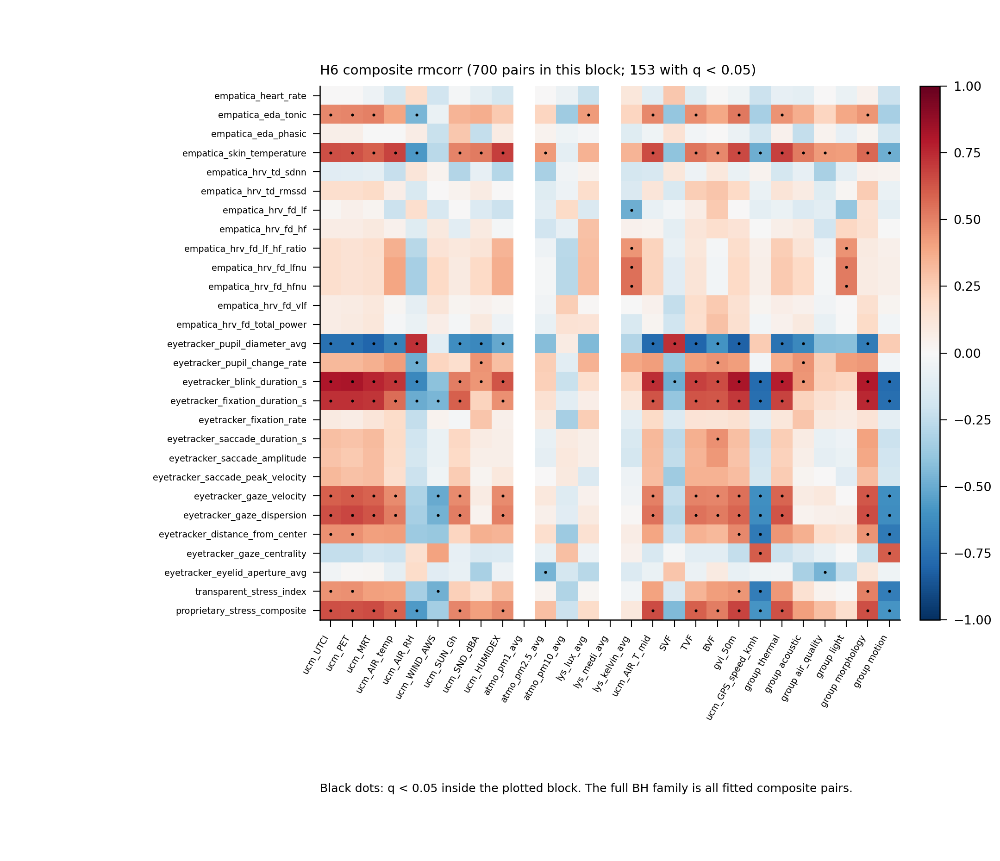

In [13]:
# Figure S5 — current H6 composite rmcorr
def figS5():
    h6 = _read_result_csv(src("res/H6/H6_pairwise_rmcorr.csv", r"output\statistical_analysis\results\H6_stress_composite\H6_pairwise_rmcorr.csv"))
    defs = _read_result_csv(src("res/H6/H6_composite_definitions.csv", r"output\statistical_analysis\results\H6_stress_composite\H6_composite_definitions.csv"))
    rows_ = list(defs[defs.domain.isin(["physiological", "ocular_transparent", "ocular_proprietary"])].composite_id)
    cols_ = list(defs[defs.domain.isin(["environmental", "environmental_group"])].composite_id)
    key = {}
    for _, r in h6.iterrows():
        key[(r.outcome, r.term)] = r
        key[(r.term, r.outcome)] = r
    R = np.full((len(rows_), len(cols_)), np.nan)
    Q = np.full_like(R, np.nan)
    for i, a_ in enumerate(rows_):
        for j, b_ in enumerate(cols_):
            r = key.get((a_, b_))
            if r is None:
                continue
            note = "" if pd.isna(r.inference_note) else str(r.inference_note)
            if not note.startswith("fit_status=FIT"):
                continue
            R[i, j] = float(r.correlation)
            Q[i, j] = float(r.p_value_adjusted)
    fig = plt.figure(figsize=(7.2, 6.2))
    ax = fig.add_axes([0.32, 0.28, 0.58, 0.62])
    im = ax.imshow(R, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
    yy, xx = np.where(np.isfinite(Q) & (Q < 0.05))
    ax.scatter(xx, yy, s=2.2, color="black", lw=0)
    ax.set_yticks(range(len(rows_)))
    ax.set_yticklabels([c.replace("physio__", "").replace("eye__", "") for c in rows_], fontsize=4.6)
    ax.set_xticks(range(len(cols_)))
    ax.set_xticklabels([c.replace("env__", "").replace("env_group_", "group ") for c in cols_], rotation=60, ha="right", fontsize=4.6)
    nfit = int(np.isfinite(R).sum())
    nsig = int((np.isfinite(Q) & (Q < 0.05)).sum())
    ax.set_title("H6 composite rmcorr (%d pairs in this block; %d with q < 0.05)" % (nfit, nsig), loc="left", fontsize=7)
    fig.colorbar(im, cax=fig.add_axes([0.92, 0.28, 0.02, 0.62]), label="rmcorr r")
    fig.text(0.32, 0.08, "Black dots: q < 0.05 inside the plotted block. The full BH family is all fitted composite pairs.", fontsize=6)
    save(fig, "Figure12_H6_composites")

figS5()


## Figure S6 — Exposure-screening PCA diagnostics

Inputs (relative to `ROOT`):
* `output\statistical_analysis\Normalization & Parameter Screening\PCA-informed\All-columns two PCAs\{air_temp,sound}_pca_{scree,biplot,loadings}.png`

saved c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS6_PCA_diagnostics.png and c:\Users\sanga\Desktop\Pranav Paper3_Final\output\Paper3_Figures\FigureS6_PCA_diagnostics.pdf


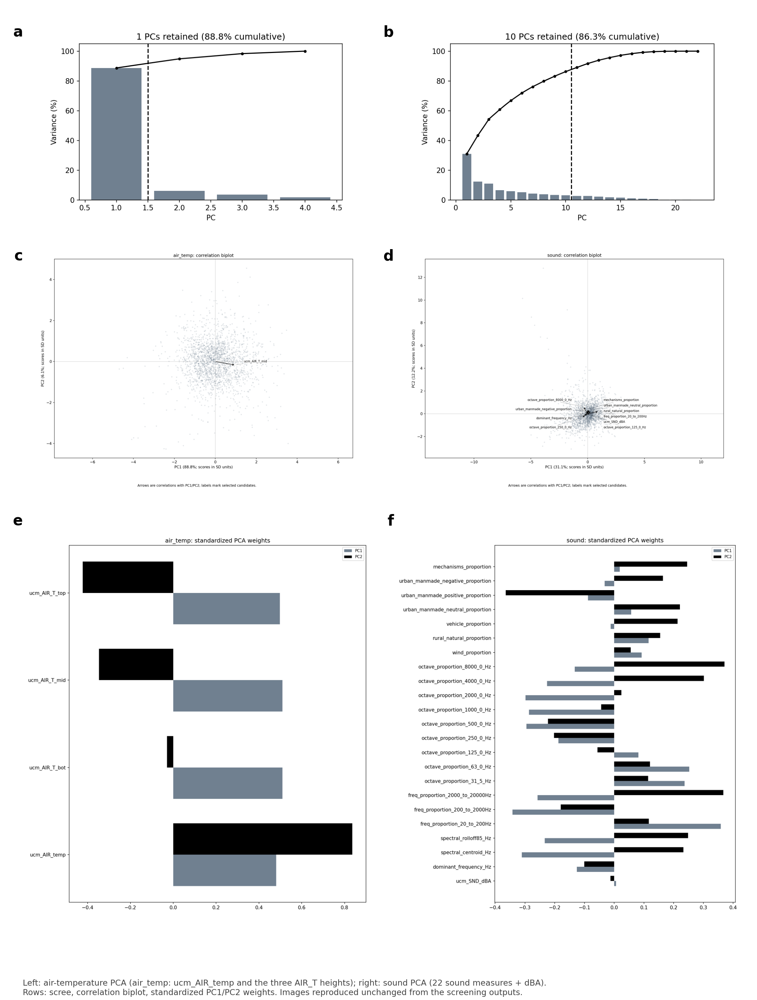

In [14]:
# Figure S6 — exposure-screening diagnostics (existing PCA outputs, composited)
def figS6():
    pdir = r"output\statistical_analysis\Normalization & Parameter Screening\PCA-informed\All-columns two PCAs" + "\\"
    fig = plt.figure(figsize=(7.2, 9.5))
    hs = [0.215, 0.25, 0.43]; gap = 0.03; y = 0.985; letters = iter("abcdef")
    for kind, h in zip(["scree", "biplot", "loadings"], hs):
        y -= h
        for column_index, grp in enumerate(["air_temp", "sound"]):
            ax = fig.add_axes([0.03 + column_index * 0.49, y, 0.46, h - 0.01])
            img_axes(ax, src(f"art/pca/{grp}_pca_{kind}.png", pdir + f"{grp}_pca_{kind}.png"))
            fig.text(0.03 + column_index * 0.49, y + h - 0.01, next(letters), fontsize=10, fontweight="bold", ha="right", va="top")
        y -= gap * (0.3 if kind == "scree" else 0.5)
    fig.text(0.03, 0.005, "Left: air-temperature PCA (air_temp: ucm_AIR_temp and the three AIR_T heights); right: sound PCA (22 sound measures + dBA).\nRows: scree, correlation biplot, standardized PC1/PC2 weights. Images reproduced unchanged from the screening outputs.",
             fontsize=5.6, color="#444444")
    save(fig, "Figure13_PCA_diagnostics")

figS6()

## Input files read in this session

In [15]:
for source_path in sorted(USED): print(source_path)

C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\manuscript_figures\Experiment timeline.png
C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\manuscript_figures\Participants matched_8min.png
C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\route_maps\Route Plan for Experiment_standard_09Jun2026.jpg
C:\Users\sanga\Desktop\Pranav Paper3_Final\Figures\sensor_setup\Experiment Sensor Setup.jpg
C:\Users\sanga\Desktop\Pranav Paper3_Final\output\merged_all_11participants_8min.csv
C:\Users\sanga\Desktop\Pranav Paper3_Final\output\statistical_analysis\Normalization & Parameter Screening\Normalization\Normalization_H1toH4_all_parameters.csv
C:\Users\sanga\Desktop\Pranav Paper3_Final\output\statistical_analysis\Normalization & Parameter Screening\PCA-informed\All-columns two PCAs\air_temp_pca_biplot.png
C:\Users\sanga\Desktop\Pranav Paper3_Final\output\statistical_analysis\Normalization & Parameter Screening\PCA-informed\All-columns two PCAs\air_temp_pca_loadings.png
C:\Users\sanga\Desktop\Pr